# NYC Yellow Taxi 2019–2023: exploratory analysis and fare prediction

This notebook analyses the TLC Yellow Taxi trip records for **five years, January 2019 to December 2023**: up to 60 monthly Parquet files and about **218 million trips**. It then builds models that predict the fare of a trip.

**Part A: exploratory analysis of all five years**
1. **Working with Parquet files in Jupyter**, and why five years need a different approach from one month
2. **Simple statistical evaluation** of every trip
3. **Target variable(s)**
4. **Regression or classification?**
5. **Missing data**: what is missing and what to do about it; cleaning; building the sample; the December 2022 fare increase
6. **Relevant vs irrelevant variables**
7. **Validation / cross-validation procedure**
8. **Data visualisation**

**Part B: year by year, and modelling**

9. **What changes from 2019 to 2023**, and the train/validation/test split
10. **Modelling**: neural network, support vector machine, random forest, Ridge/Lasso, compared against linear regression
11. **Adding more years** (2024 onwards)
12. **Summary of answers**

**How five years fit on a laptop.** All the months together would need tens of gigabytes in pandas (section 1.3). Instead, the notebook uses two tools:
- **DuckDB** gives *exact* numbers over every trip (counts, missing values, averages) by querying the Parquet files directly on disk. Nothing is loaded into pandas.
- **A 1% random sample of every month** (about 2 million trips after cleaning) is used for anything that needs individual rows: charts of distributions, correlations and the models.

Put the monthly files `yellow_tripdata_2019-01.parquet` … `yellow_tripdata_2023-12.parquet` in the same folder as this notebook, or change `DATA_DIR` below. The notebook works with whichever months are present and lists any that are missing.

## 1. Working with Parquet files in Jupyter

**What Parquet is.** A compressed, *columnar* file format. Unlike CSV it stores the column types (dates stay dates, numbers stay numbers), it is 5–10× smaller on disk, and you can read **only the columns you need**. That matters a lot with up to 8 million rows per month.

**What you need.** Pandas reads Parquet through an *engine*; `pyarrow` is the standard one. DuckDB queries Parquet files with SQL. Jupyter cannot preview a `.parquet` file by double-clicking it, so you always open it with code.

Run the install cell once, then **restart the kernel** (Kernel → Restart) so the new packages are picked up. `%pip` installs into the Python this notebook is running, which matters if you use Anaconda. The notebook needs a **Python 3** kernel (Kernel → Change kernel).

In [1]:
# Run once, then restart the kernel. Comment it out afterwards.
# %pip install -U pyarrow pandas matplotlib seaborn duckdb "scikit-learn>=1.3"

In [2]:
%pip install duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.5/15.5 MB 12.7 MB/s  0:00:01m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import gc
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# One consistent, colour-blind-safe look for every chart
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e0", "axes.edgecolor": "#b5b4ad", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left",
})

# ---- configuration -------------------------------------------------------
DATA_DIR = Path(".")                         # folder holding the parquet files
YEARS = [2019, 2020, 2021, 2022, 2023]       # add 2024, 2025 ... once those files are in DATA_DIR (section 11)
MONTHS = range(1, 13)
SAMPLE_FRAC = 0.01                           # share of every month kept for row-level analysis and models
RANDOM_STATE = 42
PLOT_SAMPLE = 500_000                        # rows used for heavy plots
CV_SAMPLE = 300_000                          # rows used for the cross-validation demo in section 7
TARIFF_CHANGE = pd.Timestamp(2022, 12, 19)   # TLC meter-rate increase (section 5.4)
DUCKDB_MEMORY = "3GB"                        # memory cap for DuckDB; raise it on a big machine

files = [DATA_DIR / f"yellow_tripdata_{y}-{m:02d}.parquet" for y in YEARS for m in MONTHS]
found = [f for f in files if f.exists()]
print(f"{len(found)} of {len(files)} monthly files found in {DATA_DIR.resolve()}")
missing_files = [f.name for f in files if not f.exists()]
if missing_files:
    print("MISSING:", missing_files)
print("duckdb", duckdb.__version__, "| pandas", pd.__version__)

60 of 60 monthly files found in /Users/ashish/Downloads/Project_2_Yellow taxi 
duckdb 1.5.6 | pandas 2.3.3


### 1.1 Look inside every file *without* loading it

`pyarrow.parquet.ParquetFile` reads only a file's footer: row count, column names and types. This is instant even for 60 files. It also shows a real problem with this data set: **the columns and types are not the same in every year** ("column drift"). The second table groups the files by schema and lists what differs from the 2019 files.

In [4]:
def month_list(months):
    # Compact list of "YYYY-MM" strings, e.g. "2019: 01-12 | 2020: 01-03, 05-07"
    out = []
    for y in sorted({m[:4] for m in months}):
        ms = sorted(int(m[5:]) for m in months if m[:4] == y)
        runs, start = [], ms[0]
        for a, b in zip(ms, ms[1:] + [None]):
            if b != a + 1:
                runs.append(f"{start:02d}" if start == a else f"{start:02d}-{a:02d}")
                start = b
        out.append(f"{y}: {', '.join(runs)}")
    return " | ".join(out)

schemas, rows = {}, []
for f in files:
    if not f.exists():
        rows.append({"file": f.name, "rows": np.nan, "columns": np.nan, "size (MB)": np.nan, "schema": "MISSING"})
        continue
    pf = pq.ParquetFile(f)
    s = pf.schema_arrow
    key = tuple(f"{n}: {t}" for n, t in zip(s.names, s.types))
    schemas.setdefault(key, []).append(f.stem[-7:])
    rows.append({"file": f.name, "rows": pf.metadata.num_rows, "columns": pf.metadata.num_columns,
                 "size (MB)": round(f.stat().st_size / 1e6), "schema": f"v{list(schemas).index(key) + 1}"})

overview = pd.DataFrame(rows).set_index("file")
print(f"{len(found)} of {len(files)} files | {overview.rows.sum():,.0f} rows | {overview['size (MB)'].sum():,.0f} MB on disk")
overview.groupby(overview.index.str[16:20]).agg(
    files=("rows", "count"), rows=("rows", "sum"), size_MB=("size (MB)", "sum")).astype("int64").rename_axis("year")

60 of 60 files | 218,118,168 rows | 3,348 MB on disk


,files,rows,size_MB
year,,,
2019,12,84598444,1242
2020,12,24649092,374
2021,12,30904308,480
2022,12,39656098,616
2023,12,38310226,636


In [5]:
# The different schemas, and what changed compared with the first file
base = dict(k.split(": ", 1) for k in next(iter(schemas)))
versions = []
for i, (key, months) in enumerate(schemas.items(), 1):
    cols = dict(k.split(": ", 1) for k in key)
    diff = [f"{c}: {base[c]} -> {t}" for c, t in cols.items() if c in base and base[c] != t]
    diff += [f"new column {c} ({t})" for c, t in cols.items() if c not in base]
    diff += [f"no {c}" for c in base if c not in cols]
    versions.append({"schema": f"v{i}", "files": len(months), "months": month_list(months),
                     "differences from v1": "; ".join(diff) or "(reference)"})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(versions).set_index("schema"))

,files,months,differences from v1
schema,,,
v1,20,"2019: 01-12 | 2020: 01-07, 10",(reference)
v2,29,"2020: 08-09, 11-12 | 2021: 01-12 | 2022: 01-12 | 2023: 01",airport_fee: null -> double
v3,11,2023: 02-12,VendorID: int64 -> int32; passenger_count: double -> int64; RatecodeID: double -> int64; store_and_fwd_flag: string -> large_string; PULocationID: int64 -> int32; DOLocationID: int64 -> int32; new column Airport_fee (double); no airport_fee


In [6]:
first_schema = pq.ParquetFile(found[0]).schema_arrow.remove_metadata()
first_schema      # the columns and types of the first file

VendorID: int64
tpep_pickup_datetime: timestamp[us]
tpep_dropoff_datetime: timestamp[us]
passenger_count: double
trip_distance: double
RatecodeID: double
store_and_fwd_flag: string
PULocationID: int64
DOLocationID: int64
payment_type: int64
fare_amount: double
extra: double
mta_tax: double
tip_amount: double
tolls_amount: double
improvement_surcharge: double
total_amount: double
congestion_surcharge: double
airport_fee: null

Three kinds of drift: `airport_fee` is an empty (`null`-typed) column until 2020 and a number afterwards; from February 2023 it is spelled **`Airport_fee`**; and the 2023 files store `passenger_count` and `RatecodeID` as integers instead of decimals and the IDs as 32-bit integers. Reading files one by one with pandas would give mismatching columns. Both tools used below handle this: DuckDB's `union_by_name` lines up columns by (case-insensitive) name, and `load_month` (section 5.3) renames and converts each file to one common format.

### 1.2 Useful ways to read Parquet

| Need | Code |
|---|---|
| Read one whole file | `pd.read_parquet(path)` |
| Read only some columns (much less memory) | `pd.read_parquet(path, columns=["fare_amount", "trip_distance"])` |
| Filter rows while reading | `pd.read_parquet(path, filters=[("fare_amount", ">", 0)])` |
| Peek at the first rows | `next(pq.ParquetFile(path).iter_batches(batch_size=5)).to_pandas()` |
| Query **many files at once** without loading them | `duckdb.sql("SELECT count(*) FROM read_parquet(['a.parquet', 'b.parquet'], union_by_name = true)")` |
| Save a table | `df.to_parquet("my_table.parquet", index=False)` |

In [7]:
# Peek at 5 rows of the first month without loading the file
next(pq.ParquetFile(found[0]).iter_batches(batch_size=5)).to_pandas()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2019-01-01 00:46:40,2019-01-01 00:53:20,1.000,1.500,1.000,N,151,239,1,7.000,0.500,0.500,1.650,0.000,0.300,9.950,NaN,None
1,1,2019-01-01 00:59:47,2019-01-01 01:18:59,1.000,2.600,1.000,N,239,246,1,14.000,0.500,0.500,1.000,0.000,0.300,16.300,NaN,None
2,2,2018-12-21 13:48:30,2018-12-21 13:52:40,3.000,0.000,1.000,N,236,236,1,4.500,0.500,0.500,0.000,0.000,0.300,5.800,NaN,None
3,2,2018-11-28 15:52:25,2018-11-28 15:55:45,5.000,0.000,1.000,N,193,193,2,3.500,0.500,0.500,0.000,0.000,0.300,7.550,NaN,None
4,2,2018-11-28 15:56:57,2018-11-28 15:58:33,5.000,0.000,2.000,N,193,193,2,52.000,0.000,0.500,0.000,0.000,0.300,55.550,NaN,None


### 1.3 Why five years can't simply be loaded into pandas

The cell loads **one** month (January 2019, one of the biggest), measures its memory, shrinks it by down-casting the types, and scales that up to all the files. The `downcast` function is used again later for the sample.

In [8]:
def downcast(df):
    # Smaller types: IDs fit in small integers, money in 32-bit floats, flags are categories
    df = df.copy()
    for c in ["VendorID", "PULocationID", "DOLocationID", "payment_type"]:
        if c in df: df[c] = pd.to_numeric(df[c], downcast="integer")
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    if "store_and_fwd_flag" in df: df["store_and_fwd_flag"] = df["store_and_fwd_flag"].astype("category")
    return df

In [9]:
%%time
one_month = pd.read_parquet(found[0])
gb_full = one_month.memory_usage(deep=True).sum() / 1e9
gb_small = downcast(one_month).memory_usage(deep=True).sum() / 1e9
scale = overview.rows.sum() / len(one_month)
print(f"{found[0].name}: {len(one_month):,} rows -> {gb_full:.2f} GB in pandas ({gb_small:.2f} GB down-cast)")
print(f"all {len(found)} files, {overview.rows.sum():,.0f} rows -> about {gb_full * scale:.0f} GB ({gb_small * scale:.0f} GB down-cast)")
del one_month
gc.collect();

yellow_tripdata_2019-01.parquet: 7,696,617 rows -> 1.62 GB in pandas (0.70 GB down-cast)
all 60 files, 218,118,168 rows -> about 46 GB (20 GB down-cast)
CPU times: user 3.08 s, sys: 1.45 s, total: 4.52 s
Wall time: 4.04 s


### 1.4 The approach: DuckDB for exact numbers, a 1% sample for rows

**DuckDB** runs SQL directly on the Parquet files. It streams through them in parallel and never needs all the data in memory, so it handles all 218 million trips; most queries take seconds, the biggest two or three minutes. The cell below creates a *view* called `all_trips` over every file. A view is a saved query, not a copy of the data. `union_by_name = true` lines up the columns by name across the different schemas from 1.1, and `filename = true` adds each row's source file, from which `file_month` is extracted. `memory_limit` keeps DuckDB within `DUCKDB_MEMORY` on a laptop.

Sections 2, 5, 8 and 9 use `sql("...")` on this view for exact numbers. The 1% monthly sample is built in section 5.3, once the cleaning rules are defined.

In [10]:
con = duckdb.connect()
con.execute(f"SET memory_limit = '{DUCKDB_MEMORY}'")

# The file list is written into the SQL (single quotes escaped), which works in every DuckDB version
file_list = [f.resolve().as_posix() for f in found]
files_sql = "[" + ", ".join("'" + p.replace("'", "''") + "'" for p in file_list) + "]"
con.execute(rf'''
    CREATE OR REPLACE VIEW all_trips AS
    SELECT *, regexp_extract(filename, '(\d{{4}}-\d{{2}})\.parquet$', 1) AS file_month
    FROM read_parquet({files_sql}, filename = true, union_by_name = true)
''')

def sql(query):
    # Run a DuckDB query and return a pandas DataFrame
    return con.sql(query).df()

sql("SELECT count(*) AS trips, count(DISTINCT file_month) AS months FROM all_trips")

,trips,months
0,218118168,60


In [11]:
sql("DESCRIBE all_trips")[["column_name", "column_type"]].T      # one common set of columns over all files

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
column_name,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,filename,file_month
column_type,BIGINT,TIMESTAMP,TIMESTAMP,DOUBLE,DOUBLE,DOUBLE,VARCHAR,BIGINT,BIGINT,BIGINT,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,VARCHAR,VARCHAR


## 2. Simple statistical evaluation (all trips, 2019–2023)

Column meanings come from the TLC data dictionary:

| Column | Meaning |
|---|---|
| `VendorID` | Technology provider (1 = Creative Mobile, 2 = Curb/VeriFone; 4, 5 and 6 appear rarely) |
| `tpep_pickup_datetime`, `tpep_dropoff_datetime` | Meter on / meter off |
| `passenger_count` | Entered by the driver |
| `trip_distance` | Miles reported by the meter |
| `RatecodeID` | 1 Standard, 2 JFK (flat fare), 3 Newark, 4 Nassau/Westchester, 5 Negotiated, 6 Group ride, 99 Unknown |
| `store_and_fwd_flag` | Y = record stored in the car and sent later (no connection) |
| `PULocationID`, `DOLocationID` | TLC taxi zone (1–263; 264/265 = unknown) |
| `payment_type` | 1 Credit card, 2 Cash, 3 No charge, 4 Dispute, 5 Unknown, 6 Voided (0 = no record) |
| `fare_amount` | Time-and-distance meter fare (or the flat fare) |
| `extra`, `mta_tax`, `improvement_surcharge`, `congestion_surcharge`, `airport_fee` | Fixed surcharges and taxes (`airport_fee`: pick-ups at LaGuardia and JFK, from 2021) |
| `tip_amount` | Tip, **only recorded for card payments** (cash tips are not captured) |
| `tolls_amount`, `total_amount` | Tolls; total charged to the passenger |

The summary below is the five-year equivalent of `df.describe()`. Count, mean, standard deviation, minimum and maximum are exact. The quartiles are DuckDB's fast approximation (`approx_quantile`), accurate to a few cents at this size. It takes two or three minutes.

In [12]:
%%time
NUM_COLS = ["passenger_count", "trip_distance", "fare_amount", "extra", "mta_tax", "tip_amount",
            "tolls_amount", "improvement_surcharge", "total_amount", "congestion_surcharge", "airport_fee"]
aggs = []
for c in NUM_COLS:
    aggs += [f'count({c}) AS "{c}|count"', f'avg({c}) AS "{c}|mean"', f'stddev_samp({c}) AS "{c}|std"',
             f'min({c}) AS "{c}|min"', f'approx_quantile({c}, 0.25) AS "{c}|25%"',
             f'approx_quantile({c}, 0.50) AS "{c}|50%"', f'approx_quantile({c}, 0.75) AS "{c}|75%"',
             f'max({c}) AS "{c}|max"']
row = sql("SELECT " + ", ".join(aggs) + " FROM all_trips").iloc[0]
row.index = pd.MultiIndex.from_tuples([tuple(k.split("|")) for k in row.index])
summary_stats = row.unstack()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].loc[NUM_COLS]
summary_stats

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 4min 56s, sys: 2.2 s, total: 4min 59s
Wall time: 41.9 s


,count,mean,std,min,25%,50%,75%,max
passenger_count,"212,707,464.000",1.471,1.084,0.000,1.000,1.000,1.775,112.000
trip_distance,"218,118,168.000",4.352,395.689,"-37,264.530",1.016,1.735,3.243,"389,678.460"
fare_amount,"218,118,168.000",13.862,"9,521.964","-133,391,414.000",7.000,10.045,16.331,"998,310.030"
extra,"218,118,168.000",1.149,33.890,-60.000,0.000,0.500,2.500,"500,000.800"
mta_tax,"218,118,168.000",0.494,33.855,-0.550,0.500,0.500,0.500,"500,000.500"
tip_amount,"218,118,168.000",3.350,"9,520.522",-493.220,0.000,2.006,3.237,"133,391,363.530"
tolls_amount,"218,118,168.000",0.441,1.914,-99.990,0.000,0.000,0.000,"3,288.000"
improvement_surcharge,"218,118,168.000",0.421,0.278,-1.000,0.300,0.300,0.300,1.000
total_amount,"218,118,168.000",21.255,183.002,"-2,567.800",11.853,15.908,23.051,"1,084,772.170"
congestion_surcharge,"207,851,246.000",2.245,0.788,-2.500,2.500,2.500,2.500,4.500


In [13]:
# Trips per year (by source file) and the range of pickup dates
display(sql('''
    SELECT substr(file_month, 1, 4) AS year, count(DISTINCT file_month) AS months, count(*) AS trips
    FROM all_trips GROUP BY 1 ORDER BY 1
''').set_index("year").T)
sql(f'''
    SELECT min(tpep_pickup_datetime) AS earliest_pickup,
           max(tpep_pickup_datetime) AS latest_pickup,
           CAST(sum(CASE WHEN year(tpep_pickup_datetime) NOT BETWEEN {YEARS[0]} AND {YEARS[-1]} THEN 1 ELSE 0 END) AS BIGINT)
               AS pickups_outside_{YEARS[0]}_{YEARS[-1]}
    FROM all_trips
''')

year,2019,2020,2021,2022,2023
months,12,12,12,12,12
trips,84598444,24649092,30904308,39656098,38310226


,earliest_pickup,latest_pickup,pickups_outside_2019_2023
0,2001-01-01 00:02:08,2098-09-11 02:23:31,2047


In [13]:
# Categorical columns: % of each year's trips with each code ("null" = missing)
def code_label(v):
    if pd.isna(v): return "null"
    return str(int(v)) if isinstance(v, (int, float, np.integer, np.floating)) else str(v)

for c in ["VendorID", "RatecodeID", "payment_type", "store_and_fwd_flag", "passenger_count"]:
    vc = sql(f"SELECT substr(file_month, 1, 4) AS year, {c} AS code, count(*) AS n FROM all_trips GROUP BY ALL")
    vc["code"] = vc["code"].map(code_label)
    tab = vc.pivot_table(index="code", columns="year", values="n", aggfunc="sum").fillna(0)
    display((tab / tab.sum() * 100).round(2).rename_axis(f"{c} (% of trips)", axis=0))

year,2019,2020,2021,2022,2023
VendorID (% of trips),,,,,
1,35.900,32.480,30.200,28.420,26.200
2,63.790,67.340,69.400,71.430,73.780
4,0.320,0.000,0.000,0.000,0.000
5,0.000,0.000,0.000,0.000,0.000
6,0.000,0.180,0.400,0.150,0.020


year,2019,2020,2021,2022,2023
RatecodeID (% of trips),,,,,
1,95.940,94.250,92.180,91.230,91.080
2,2.640,1.740,2.250,3.790,3.850
3,0.230,0.160,0.170,0.280,0.330
4,0.080,0.080,0.110,0.130,0.200
5,0.580,0.490,0.460,0.790,0.570
6,0.000,0.000,0.000,0.000,0.000
99,0.000,0.000,0.040,0.340,0.560
null,0.530,3.290,4.780,3.450,3.420


year,2019,2020,2021,2022,2023
payment_type (% of trips),,,,,
0,0.530,3.290,4.780,3.450,3.420
1,71.660,70.850,72.740,75.870,77.930
2,27.070,24.940,21.580,19.580,16.720
3,0.530,0.590,0.500,0.490,0.630
4,0.220,0.330,0.390,0.620,1.300
5,0.000,0.000,0.000,0.000,0.000


year,2019,2020,2021,2022,2023
store_and_fwd_flag (% of trips),,,,,
N,98.660,95.720,93.860,95.250,96.000
Y,0.820,1.000,1.360,1.300,0.580
null,0.530,3.290,4.780,3.450,3.420


year,2019,2020,2021,2022,2023
passenger_count (% of trips),,,,,
0,1.800,1.990,2.280,1.920,1.520
1,69.870,71.040,69.570,71.270,72.630
112,0.000,0.000,0.000,0.000,0.000
2,15.110,13.590,14.310,14.790,14.640
3,4.240,3.540,3.770,3.890,3.640
4,2.020,1.580,1.510,1.790,2.060
5,4.020,3.050,2.320,1.730,1.260
6,2.410,1.930,1.460,1.160,0.830
7,0.000,0.000,0.000,0.000,0.000


### 2.1 Sanity checks: the data set is "difficult" for a reason

The summary table already shows impossible values: negative distances (as low as −37,264 miles), fares from about −$133 million to almost $1 million, and pickups dated from 2001 to 2098. The cell below counts each kind of problem **exactly, across all trips**, so it can be handled deliberately.

In [14]:
%%time
sanity_counts = sql('''
    SELECT
      sum(CASE WHEN strftime(tpep_pickup_datetime, '%Y-%m') <> file_month THEN 1 ELSE 0 END)          AS "pickup outside its file's month",
      sum(CASE WHEN date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) <= 0 THEN 1 ELSE 0 END) AS "duration <= 0 min",
      sum(CASE WHEN date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) > 10800 THEN 1 ELSE 0 END) AS "duration > 3 h",
      sum(CASE WHEN trip_distance < 0 THEN 1 ELSE 0 END)                                              AS "trip_distance < 0",
      sum(CASE WHEN trip_distance = 0 THEN 1 ELSE 0 END)                                              AS "trip_distance = 0",
      sum(CASE WHEN trip_distance > 100 THEN 1 ELSE 0 END)                                            AS "trip_distance > 100 mi",
      sum(CASE WHEN fare_amount <= 0 THEN 1 ELSE 0 END)                                               AS "fare_amount <= 0",
      sum(CASE WHEN fare_amount > 500 THEN 1 ELSE 0 END)                                              AS "fare_amount > 500",
      sum(CASE WHEN least(fare_amount, extra, mta_tax, tip_amount, tolls_amount,
                          improvement_surcharge, total_amount) < 0 THEN 1 ELSE 0 END)                 AS "any negative money column",
      sum(CASE WHEN passenger_count = 0 THEN 1 ELSE 0 END)                                            AS "passenger_count = 0",
      sum(CASE WHEN RatecodeID = 99 THEN 1 ELSE 0 END)                                                AS "RatecodeID = 99 (unknown)",
      sum(CASE WHEN PULocationID IN (264, 265) OR DOLocationID IN (264, 265) THEN 1 ELSE 0 END)       AS "pickup or dropoff zone 264/265 (unknown)",
      count(*)                                                                                        AS total_trips
    FROM all_trips
''').iloc[0]
TOTAL_TRIPS = int(sanity_counts.pop("total_trips"))
sanity = sanity_counts.astype(int).to_frame("rows")
sanity["% of trips"] = sanity["rows"] / TOTAL_TRIPS * 100
sanity.sort_values("rows", ascending=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 48.8 s, sys: 1.8 s, total: 50.6 s
Wall time: 7.94 s


,rows,% of trips
passenger_count = 0,4065487,1.864
pickup or dropoff zone 264/265 (unknown),3439885,1.577
trip_distance = 0,2829096,1.297
fare_amount <= 0,1126335,0.516
any negative money column,1043280,0.478
duration > 3 h,417024,0.191
RatecodeID = 99 (unknown),363875,0.167
duration <= 0 min,223463,0.102
trip_distance < 0,11440,0.005
pickup outside its file's month,10507,0.005


## 3. Target variable(s)

The data set has no label column, so the target is a **choice** that depends on the question the model answers. Three sensible options:

| Candidate target | Question it answers | Task type |
|---|---|---|
| **`fare_amount`** *(main choice)* | "How much will this trip cost?": an up-front fare estimate | Regression |
| `trip_duration` (dropoff − pickup, in minutes) | "How long will this trip take?": an ETA | Regression |
| `tip_given` = `tip_amount > 0` (card trips only) | "Will this passenger tip?" | Classification |

**Recommended main target: `fare_amount`.** It is clean to define, available for every trip, and directly linked to features known when a trip starts (pickup time, pickup/dropoff zone, distance).

Why **not** `total_amount`? It is `fare_amount` + tip + tolls + surcharges. The tip is decided *after* the ride, so a model predicting the total would be partly guessing passenger generosity, and every one of those parts would leak the answer if used as a feature.

Over five years there is one complication: the meter's prices changed on **19 December 2022**. Section 5.4 shows the change and how the models deal with it: they learn from every year's fares **converted to the 2023 price list** (`fare_2023`) and are tested on real 2023 fares.

`TARGET` below controls the exploratory sections; switch it to `"trip_duration"` to repeat the analysis for the ETA question.

In [15]:
TARGET = "fare_amount"      # or "trip_duration"

## 4. Regression or classification?

`fare_amount` (and `trip_duration`) are **continuous numbers**, so this is a **regression** task. Suitable metrics: **MAE** (average dollars off, easy to explain), **RMSE** (punishes big misses), and **R²**.

If you choose the tipping target instead, it becomes **binary classification** (metrics: ROC-AUC, F1). Two warnings for that option: use only `payment_type == 1` (card) trips, because cash tips are recorded as 0 even when a tip was paid; and about 96% of card trips tip in every year, so the classes are imbalanced and accuracy alone is misleading.

## 5. Missing data

There are two kinds of missing values in this data set:

1. **Explicit missing**: actual `NaN`/`null` values.
2. **Disguised missing**: a number that really means "unknown": `passenger_count = 0`, `RatecodeID = 99`, `payment_type = 0`, zones 264/265, `trip_distance = 0`.

All counts below are exact, over every trip in the five years.

In [16]:
%%time
cols = [c for c in sql("DESCRIBE all_trips").column_name if c not in ("filename", "file_month")]
nulls = sql("SELECT " + ", ".join(f'count(*) - count("{c}") AS "{c}"' for c in cols) + " FROM all_trips").iloc[0]
missing = pd.DataFrame({"missing rows": nulls.astype(int), "% missing": nulls / TOTAL_TRIPS * 100})
missing = missing[missing["missing rows"] > 0].sort_values("% missing", ascending=False)
missing

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 23.1 s, sys: 1.73 s, total: 24.8 s
Wall time: 4.42 s


,missing rows,% missing
airport_fee,117566592,53.900
congestion_surcharge,10266922,4.707
passenger_count,5410704,2.481
RatecodeID,5410704,2.481
store_and_fwd_flag,5410704,2.481


In [17]:
# When are the gaps? (% of each year's trips)
sql('''
    SELECT substr(file_month, 1, 4) AS year,
           100 * avg(CASE WHEN passenger_count      IS NULL THEN 1 ELSE 0 END) AS "% no meter record (passenger_count null)",
           100 * avg(CASE WHEN congestion_surcharge IS NULL THEN 1 ELSE 0 END) AS "% congestion_surcharge null",
           100 * avg(CASE WHEN airport_fee          IS NULL THEN 1 ELSE 0 END) AS "% airport_fee null"
    FROM all_trips GROUP BY 1 ORDER BY 1
''').set_index("year").T

year,2019,2020,2021,2022,2023
% no meter record (passenger_count null),0.525,3.286,4.785,3.450,3.418
% congestion_surcharge null,6.266,3.286,4.785,3.450,3.418
% airport_fee null,100.000,100.000,18.254,3.450,3.418


In [18]:
# Do the gaps happen on the SAME rows?
sql('''
    SELECT
      sum(CASE WHEN passenger_count IS NULL AND RatecodeID IS NULL AND store_and_fwd_flag IS NULL THEN 1 ELSE 0 END) AS "all three null",
      sum(CASE WHEN passenger_count IS NULL OR  RatecodeID IS NULL OR  store_and_fwd_flag IS NULL THEN 1 ELSE 0 END) AS "any of the three null",
      sum(CASE WHEN passenger_count IS NULL AND payment_type = 0 THEN 1 ELSE 0 END)                                AS "  ...of which payment_type = 0",
      sum(CASE WHEN congestion_surcharge IS NULL AND file_month <> '2019-01' THEN 1 ELSE 0 END)                    AS "congestion_surcharge null after Jan 2019",
      sum(CASE WHEN congestion_surcharge IS NULL AND file_month <> '2019-01'
                    AND passenger_count IS NULL THEN 1 ELSE 0 END)                                                   AS "  ...of which no meter record",
      sum(CASE WHEN airport_fee IS NULL AND file_month >= '2022-01' THEN 1 ELSE 0 END)                             AS "airport_fee null from 2022",
      sum(CASE WHEN airport_fee IS NULL AND file_month >= '2022-01' AND passenger_count IS NULL THEN 1 ELSE 0 END) AS "  ...of which no meter record "
    FROM all_trips
''').T.rename(columns={0: "trips"}).astype("int64")

,trips
all three null,5410704
any of the three null,5410704
...of which payment_type = 0,5410704
congestion_surcharge null after Jan 2019,5382035
...of which no meter record,5382032
airport_fee null from 2022,2677659
...of which no meter record,2677659


In [19]:
# Are rows without a meter record just like the others? (approximate medians)
sql('''
    SELECT substr(file_month, 1, 4) AS year, passenger_count IS NULL AS no_meter_record, count(*) AS trips,
           round(approx_quantile(fare_amount, 0.5), 2)   AS median_fare,
           round(approx_quantile(trip_distance, 0.5), 2) AS median_miles,
           round(100 * avg(CASE WHEN tip_amount > 0 THEN 1 ELSE 0 END), 1) AS pct_tipped
    FROM all_trips GROUP BY ALL ORDER BY 1, 2
''').set_index(["year", "no_meter_record"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

trips  median_fare  median_miles  pct_tipped
year no_meter_record                                                 
2019 False            84154061        9.500         1.630      69.200
     True               444383       36.070         9.030       0.600
2020 False            23839125        8.950         1.610      70.400
     True               809967       25.390         5.820      61.000
2021 False            29425613        9.380         1.780      73.300
     True              1478695       21.120         4.140      55.200
2022 False            38287795       10.010         1.860      75.500
     True              1368303       16.410         3.010      86.600
2023 False            37000870       13.450         1.780      76.900
     True              1309356       18.650         2.130      60.500

**What to do about each one** (exact counts over all 218,118,168 trips)

| Column | What's going on | Action |
|---|---|---|
| `airport_fee` | 53.90% null (117,566,592 trips). The column is empty in every 2019 and 2020 file and in early 2021, because the fee on LaGuardia and JFK pick-ups ($1.25, later $1.75) only started in spring 2021. From 2022 it is missing only on the rows with no meter record (row 3). | **Fill with 0** where the fee didn't exist yet: "not charged" is a real 0, not unknown. It is a surcharge, not part of the fare, so it is not a feature. |
| `congestion_surcharge` | 4.71% null (10,266,922). 4,884,887 are January 2019 trips, before the surcharge started on 2 February 2019. The other 5,382,035 are, all but 3, the rows with no meter record. | **Fill with 0** in January 2019. Not a feature. |
| `passenger_count`, `RatecodeID`, `store_and_fwd_flag` | 5,410,704 trips (2.48%) are null in **all three at once**, and every one has `payment_type = 0`: trips without a full meter record. The share jumps from 0.53% in 2019 to 3.29% in 2020 (16.9% in May 2020) and stays at 3–5% afterwards. These rows are **not like the others**: in 2019 their median fare is about $36 for 9 miles (against $9.50 for 1.6 miles), in 2023 about $18.70 against $13.50. | Not missing at random, and the rate code (a key feature) is unknown, so **drop the rows**. |
| `passenger_count = 0` | 4,065,487 trips (1.86%): the driver didn't enter it. | Treat as missing: impute the **mode (1)** and add a flag column `passenger_unknown`. |
| `RatecodeID = 99` | 363,875 trips (0.17%): unknown rate. Almost none in 2019, 0.56% of trips in 2023. | **Drop**. |
| Zones 264 / 265 | 3,439,885 trips (1.58%): location unknown. | **Drop** for the fare model (location is a key feature). |
| `trip_distance ≤ 0`, `fare_amount ≤ 0`, negative amounts | 2,829,096 zero-distance and 11,440 negative-distance trips, 1,126,335 fares of $0 or less, 1,043,280 trips with a negative charge: cancelled trips, refunds and meter errors. All become more common after 2020. | **Drop**: these are invalid records, not missing values to impute. |
| Whole days with very few trips | Sunday 18 September 2022 (4,229 trips) and 22–24 September 2023 (4,600–5,700 a day) against about 100,000 on the surrounding days, spread thinly over every hour (section 8.4): most of those days' records are missing from the published files. | Keep the trips that are there (they are valid), but don't read these days as real demand. |

General rule used here: **impute** only when the value is genuinely unknown *and* the row is otherwise good; **drop** when the row itself is broken; **fill with 0** when "missing" really means "not charged".

### 5.1 Cleaning function

All the rules live in one function, so every month of every year is cleaned the same way. Thresholds are deliberately loose: they remove broken records, not unusual but real trips. `clean_trips` works on one month at a time because the "pickup outside month" rule needs to know which month the file is for.

In [20]:
def clean_trips(df, year, month):
    df = df.copy()
    n0 = len(df)
    log = {}
    def keep(mask, why):
        nonlocal df
        log[why] = int((~mask).sum())
        df = df[mask]

    start = pd.Timestamp(year, month, 1)
    end = start + pd.offsets.MonthBegin(1)
    df["trip_duration"] = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60

    keep(df.tpep_pickup_datetime.between(start, end, inclusive="left"), "pickup outside month")
    keep(df[["passenger_count", "RatecodeID"]].notna().all(axis=1), "incomplete meter record")
    keep(df.trip_duration.between(1, 180), "duration not in 1-180 min")
    keep(df.trip_distance.between(0.1, 100), "distance not in 0.1-100 mi")
    keep(df.fare_amount.between(2.5, 500), "fare not in $2.50-$500")
    keep(df.RatecodeID.between(1, 6), "unknown rate code")
    keep(~df.PULocationID.isin([264, 265]) & ~df.DOLocationID.isin([264, 265]), "unknown zone")
    speed = df.trip_distance / (df.trip_duration / 60)
    keep(speed.between(0.5, 80), "avg speed not in 0.5-80 mph")
    money = ["extra", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "total_amount"]
    keep((df[money] >= 0).all(axis=1), "negative charge (refund)")

    # disguised-missing handling
    df["passenger_unknown"] = (df.passenger_count == 0).astype("int8")
    df.loc[df.passenger_count == 0, "passenger_count"] = 1
    df["passenger_count"] = df.passenger_count.astype("int8")
    df["RatecodeID"] = df.RatecodeID.astype("int8")
    for fee in ["congestion_surcharge", "airport_fee", "Airport_fee", "cbd_congestion_fee"]:
        if fee in df: df[fee] = pd.to_numeric(df[fee], errors="coerce").fillna(0)

    report = pd.Series(log, name="rows removed")
    report.loc["TOTAL removed"] = n0 - len(df)
    report = report.to_frame()
    report["% of original"] = report["rows removed"] / n0 * 100
    return df.reset_index(drop=True), report

### 5.2 Feature engineering

Features that a model can know **at the moment the trip starts**. `new_tariff` marks the meter prices in force (section 5.4).

In [21]:
def add_features(df):
    t = df.tpep_pickup_datetime
    df["pickup_hour"] = t.dt.hour.astype("int8")
    df["pickup_dow"] = t.dt.dayofweek.astype("int8")          # 0 = Monday
    df["is_weekend"] = (df.pickup_dow >= 5).astype("int8")
    df["pickup_day"] = t.dt.day.astype("int8")
    df["pickup_month"] = t.dt.month.astype("int8")
    df["pickup_year"] = t.dt.year.astype("int16")
    df["new_tariff"] = (t >= TARIFF_CHANGE).astype("int8")    # 1 = meter rates in force from 19 Dec 2022
    df["same_zone"] = (df.PULocationID == df.DOLocationID).astype("int8")
    df["airport_trip"] = (df.PULocationID.isin([1, 132, 138]) | df.DOLocationID.isin([1, 132, 138])).astype("int8")  # EWR, JFK, LGA
    return df

### 5.3 Build the five-year sample, one month at a time

`load_month` reads one file and keeps only the needed columns. It harmonises the schema drift from 1.1 (`Airport_fee` becomes `airport_fee`; integer and decimal columns end up with the same types), fills fees that didn't exist yet with 0, takes a **1% random sample**, and runs `clean_trips` and `add_features`. `load_range` loops over the months, so only one month is ever in memory. Taking the same share of every month keeps each month's weight proportional to its real number of trips.

The sample is saved as a Parquet file and reloaded on the next run. The cell **checks that the saved file covers exactly the months now in the folder** and rebuilds it if not, so adding a missing month (or a new year) is picked up automatically. Building it from scratch takes about a minute.

In [22]:
KEEP_COLS = ["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance",
             "RatecodeID", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "extra", "mta_tax",
             "tip_amount", "tolls_amount", "improvement_surcharge", "total_amount", "congestion_surcharge",
             "airport_fee", "cbd_congestion_fee"]

def load_month(year, month, frac=None, data_dir=DATA_DIR, seed=RANDOM_STATE):
    # Load, harmonise, sample, clean and feature-engineer one monthly file
    path = Path(data_dir) / f"yellow_tripdata_{year}-{month:02d}.parquet"
    available = {c.lower(): c for c in pq.ParquetFile(path).schema_arrow.names}
    cols = [available[c.lower()] for c in KEEP_COLS if c.lower() in available]
    d = pd.read_parquet(path, columns=cols)
    d.columns = [c if c.startswith("tpep") or c in ("VendorID", "RatecodeID", "PULocationID", "DOLocationID")
                 else c.lower() for c in d.columns]                      # Airport_fee -> airport_fee
    for c in KEEP_COLS:                                                  # fees that didn't exist yet = 0
        if c not in d: d[c] = 0.0
    if frac: d = d.sample(frac=frac, random_state=seed)
    d, report = clean_trips(d, year, month)
    d = downcast(add_features(d))
    return d, report

def load_range(years, months=range(1, 13), frac=SAMPLE_FRAC):
    parts, reports = [], {}
    for y in years:
        for m in months:
            p = Path(DATA_DIR) / f"yellow_tripdata_{y}-{m:02d}.parquet"
            if not p.exists():
                print(f"skip {p.name} (not found)"); continue
            d, r = load_month(y, m, frac=frac)
            parts.append(d)
            reports[f"{y}-{m:02d}"] = pd.concat([r["rows removed"], pd.Series({"rows kept": len(d)})])
            print(f"{p.name}: kept {len(d):,} sampled rows")
            gc.collect()
    return pd.concat(parts, ignore_index=True), pd.DataFrame(reports).T

SAMPLE_FILE = DATA_DIR / f"yellow_sample_{YEARS[0]}-{YEARS[-1]}_{round(SAMPLE_FRAC * 100)}pct.parquet"
REPORT_FILE = SAMPLE_FILE.with_suffix(".cleaning.csv")

In [23]:
%%time
available = {(y, m) for y in YEARS for m in MONTHS
             if (DATA_DIR / f"yellow_tripdata_{y}-{m:02d}.parquet").exists()}

trips = None
if SAMPLE_FILE.exists() and REPORT_FILE.exists():
    trips = pd.read_parquet(SAMPLE_FILE)
    removed = pd.read_csv(REPORT_FILE, index_col=0)
    saved = set(zip(trips.pickup_year.astype(int), trips.pickup_month.astype(int)))
    if saved != available or "new_tariff" not in trips:
        print(f"saved sample has {len(saved)} months but {len(available)} files exist, so rebuilding it")
        trips = None
    else:
        print(f"loaded saved sample {SAMPLE_FILE.name}")

if trips is None:
    trips, removed = load_range(YEARS, MONTHS, SAMPLE_FRAC)
    trips.to_parquet(SAMPLE_FILE, index=False)
    removed.to_csv(REPORT_FILE)
    print(f"saved {SAMPLE_FILE.name} ({SAMPLE_FILE.stat().st_size / 1e6:.0f} MB)")

df = trips   # sections 6-8 call the sample `df`, sections 9-10 call it `trips`: same table
print(f"five-year sample: {len(trips):,} trips x {trips.shape[1]} columns, "
      f"{trips.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
trips.groupby(["pickup_year", "pickup_month"]).size().unstack().astype("Int64").rename_axis(index="year", columns="month")

loaded saved sample yellow_sample_2019-2023_1pct.parquet
five-year sample: 2,051,026 trips x 30 columns, 170 MB in memory
CPU times: user 349 ms, sys: 154 ms, total: 503 ms
Wall time: 442 ms


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2019,73783,68281,76479,72414,73623,67508,60871,58517,63361,69565,66322,66420
2020,61628,60878,28834,2111,2720,4701,6951,8908,12026,15198,13656,13184
2021,12280,12257,17415,19731,23045,26158,25977,25584,27115,32149,32341,29933
2022,22966,27683,33700,33479,33232,32784,29339,29182,29252,33867,29848,31053
2023,28584,27112,31689,30574,32600,30628,26793,25955,25749,32021,30559,30453


In [24]:
# What cleaning removed, all months together (% of the sampled rows)
sampled_rows = int(removed["rows kept"].sum() + removed["TOTAL removed"].sum())
clean_report = removed.drop(columns=["rows kept"]).sum().to_frame("rows removed")
clean_report["% of sampled rows"] = clean_report["rows removed"] / sampled_rows * 100
print(f"sampled {sampled_rows:,} trips, kept {int(removed['rows kept'].sum()):,} "
      f"({removed['rows kept'].sum() / sampled_rows:.1%})")
clean_report

sampled 2,181,181 trips, kept 2,051,026 (94.0%)


,rows removed,% of sampled rows
pickup outside month,111,0.005
incomplete meter record,54085,2.480
duration not in 1-180 min,27929,1.280
distance not in 0.1-100 mi,10669,0.489
fare not in $2.50-$500,8078,0.370
unknown rate code,3065,0.141
unknown zone,25968,1.191
avg speed not in 0.5-80 mph,245,0.011
negative charge (refund),5,0.000
TOTAL removed,130155,5.967


In [25]:
df[[TARGET, "trip_distance", "pickup_hour", "pickup_dow", "is_weekend", "pickup_year", "new_tariff",
    "same_zone", "airport_trip"]].describe().T

,count,mean,std,min,25%,50%,75%,max
fare_amount,"2,051,026.000",14.094,12.302,2.500,7.000,10.000,15.600,500.000
trip_distance,"2,051,026.000",3.120,3.940,0.100,1.040,1.720,3.170,81.450
pickup_hour,"2,051,026.000",14.080,5.789,0.000,10.000,15.000,19.000,23.000
pickup_dow,"2,051,026.000",2.971,1.923,0.000,1.000,3.000,5.000,6.000
is_weekend,"2,051,026.000",0.263,0.441,0.000,0.000,0.000,1.000,1.000
pickup_year,"2,051,026.000","2,020.613",1.557,"2,019.000","2,019.000","2,020.000","2,022.000","2,023.000"
new_tariff,"2,051,026.000",0.177,0.382,0.000,0.000,0.000,0.000,1.000
same_zone,"2,051,026.000",0.044,0.205,0.000,0.000,0.000,0.000,1.000
airport_trip,"2,051,026.000",0.083,0.276,0.000,0.000,0.000,0.000,1.000


### 5.4 The December 2022 fare increase: putting five years on one price list

On **19 December 2022** the TLC raised the taxi meter rates for the first time since 2012 (NYC TLC rule *Taximeter Rate of Fare and Various Surcharges*):

| | Until 18 Dec 2022 | From 19 Dec 2022 |
|---|---|---|
| Initial charge | $2.50 | $3.00 |
| Each further unit (1/5 mile, or 60 seconds in slow traffic) | $0.50 | $0.70 |
| JFK – Manhattan flat fare | $52 | $70 |
| Newark surcharge | $17.50 | $20 |

The rush-hour, overnight and improvement surcharges and a new $5 LaGuardia surcharge also rose, but they are separate columns, not part of `fare_amount`. The first cell shows the change in the data, day by day.

In [24]:
sql('''
    SELECT CAST(tpep_pickup_datetime AS DATE) AS day,
           median(fare_amount) FILTER (WHERE RatecodeID = 1 AND trip_distance BETWEEN 1.5 AND 2.5) AS "median fare, standard trips of 1.5-2.5 mi",
           median(fare_amount) FILTER (WHERE RatecodeID = 2)                                       AS "median JFK flat fare"
    FROM all_trips
    WHERE file_month = '2022-12' AND tpep_pickup_datetime >= '2022-12-14' AND tpep_pickup_datetime < '2022-12-25'
    GROUP BY 1 ORDER BY 1
''').set_index("day").T

day,2022-12-14,2022-12-15,2022-12-16,2022-12-17,2022-12-18,2022-12-19,2022-12-20,2022-12-21,2022-12-22,2022-12-23,2022-12-24
"median fare, standard trips of 1.5-2.5 mi",10.500,11.000,10.500,10.000,9.500,12.800,13.500,13.500,13.500,12.800,12.100
median JFK flat fare,52.000,52.000,52.000,52.000,52.000,70.000,70.000,70.000,70.000,70.000,70.000


In [25]:
# The meter works in whole units: check it on the sample
std = trips[trips.RatecodeID == 1]
for label, d, start, unit in [("before 19 Dec 2022", std[std.new_tariff == 0], 2.50, 0.50),
                              ("from 19 Dec 2022  ", std[std.new_tariff == 1], 3.00, 0.70)]:
    units = (d.fare_amount.astype("float64") - start) / unit
    whole = np.mean(np.abs(units - units.round()) < 0.02) * 100
    print(f"{label}: {whole:.1f}% of {len(d):,} standard-rate fares are ${start:.2f} + a whole number of ${unit:.2f} units")

before 19 Dec 2022: 100.0% of 1,636,988 standard-rate fares are $2.50 + a whole number of $0.50 units
from 19 Dec 2022  : 99.9% of 347,706 standard-rate fares are $3.00 + a whole number of $0.70 units


**Why this matters for the models.** The test months (October–December 2023) are all under the new prices, but most of the five years are under the old ones. A model fed raw fares sees two different price lists for the same trip. A `new_tariff` flag helps, but then the model has to learn every distance, zone and time pattern twice, once per price list.

**What we do instead: convert old fares to 2023 prices.** Because a standard fare is always the initial charge plus a whole number of units, the number of units on the meter is known exactly, and the same trip under the new prices costs $3.00 + units × $0.70. JFK flat fares go from $52 to $70, and Newark trips get the new unit price and the $20 surcharge. Other rate codes (Nassau/Westchester, negotiated and group rides, under 1% of trips) are left as they are. Trips from 19 December 2022 onwards are unchanged.

The result is `fare_2023`: every trip's fare **in the prices of the 2023 meter**. The models learn from `fare_2023`, so every year contributes to learning today's prices. They are **evaluated on the real `fare_amount` of October–December 2023 trips**, which is the same thing for those trips. Section 10.2 checks on the validation months that this works better than the alternatives. The conversion assumes the same route and traffic; the remaining differences in traffic are left to the hour, day and month features. Once fares are converted, the models no longer need to be told the year or the price list: section 10.2 shows they do as well or better without `pickup_year` and `new_tariff`.

In [26]:
def harmonise_fare(df):
    # fare_amount expressed in the meter prices in force from 19 Dec 2022 ("2023 prices")
    f = df.fare_amount.astype("float64").copy()
    old = df.new_tariff == 0
    std, jfk, ewr = old & (df.RatecodeID == 1), old & (df.RatecodeID == 2), old & (df.RatecodeID == 3)
    f[std] = 3.00 + (f[std] - 2.50) / 0.50 * 0.70                    # same number of meter units, new unit price
    f[jfk] = f[jfk] + (70 - 52)                                      # JFK flat fare $52 -> $70
    f[ewr] = 20.00 + 3.00 + (f[ewr] - 17.50 - 2.50) / 0.50 * 0.70    # Newark: metered part + surcharge $17.50 -> $20
    return f.astype("float32")

trips["fare_2023"] = harmonise_fare(trips)
TRAIN_TARGET = "fare_2023"           # what the models learn (section 10); TARGET stays the real fare_amount

two_mile = trips[(trips.RatecodeID == 1) & trips.trip_distance.between(1.5, 2.5)]
jfk = trips[trips.RatecodeID == 2]
pd.DataFrame({"standard 1.5-2.5 mi: median fare_amount": two_mile.groupby("pickup_year").fare_amount.median(),
              "standard 1.5-2.5 mi: median fare_2023": two_mile.groupby("pickup_year").fare_2023.median(),
              "JFK: median fare_amount": jfk.groupby("pickup_year").fare_amount.median(),
              "JFK: median fare_2023": jfk.groupby("pickup_year").fare_2023.median()}).T.round(2)

pickup_year,2019,2020,2021,2022,2023
standard 1.5-2.5 mi: median fare_amount,10.000,9.500,9.500,10.000,13.500
standard 1.5-2.5 mi: median fare_2023,13.500,12.800,12.800,13.500,13.500
JFK: median fare_amount,52.000,52.000,52.000,52.000,70.000
JFK: median fare_2023,70.000,70.000,70.000,70.000,70.000


**Result.** Converting puts every year on the same price list. The median real fare of a standard 1.5–2.5-mile trip was $9.50–$10.00 in 2019–2022 and $13.50 in 2023. Converted, it is $12.80–$13.50 in every year, and every JFK flat fare becomes $70. The small difference that is left (2020–21: $12.80) is real: traffic was lighter during COVID, so trips spent less time on the meter's time charge (section 9.3).

## 6. Which variables are relevant or irrelevant?

Two questions decide this:

1. **Is it known when the prediction is made?** For an up-front fare estimate, anything recorded *after* the trip (tip, tolls, total, dropoff time, payment method) would be **data leakage**: it makes the validation score look great and the real model useless.
2. **Does it carry signal about the target?** Measured below on 500,000 trips from the five-year sample, with rank (Spearman) correlation for numeric columns and group medians for categorical ones.

In [27]:
sample = df.sample(min(PLOT_SAMPLE, len(df)), random_state=RANDOM_STATE)

num_cols = ["trip_distance", "trip_duration", "passenger_count", "pickup_hour", "pickup_dow", "is_weekend",
            "pickup_month", "pickup_year", "new_tariff", "same_zone", "airport_trip", "extra", "mta_tax", "tip_amount",
            "tolls_amount", "improvement_surcharge", "congestion_surcharge", "airport_fee", "total_amount", "VendorID",
            "RatecodeID", "payment_type", "PULocationID", "DOLocationID"]
num_cols = [c for c in num_cols if c in sample and c != TARGET]
corr = sample[num_cols + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
corr.sort_values(key=abs, ascending=False).to_frame("Spearman ρ with target")

,Spearman ρ with target
total_amount,0.961
trip_duration,0.951
trip_distance,0.915
airport_trip,0.447
tip_amount,0.433
tolls_amount,0.389
RatecodeID,0.302
airport_fee,0.287
same_zone,-0.257
new_tariff,0.215


In [28]:
# Location IDs are categories, so a correlation on the raw ID number is meaningless.
# Instead, check how much the median target moves between groups.
for c in ["PULocationID", "DOLocationID", "RatecodeID", "pickup_year", "pickup_month", "VendorID", "payment_type"]:
    g = sample.groupby(c)[TARGET].median()
    print(f"{c:13s}  {g.size:3d} groups | median {TARGET} ranges ${g.min():,.2f} – ${g.max():,.2f}")

PULocationID   241 groups | median fare_amount ranges $5.50 – $117.50
DOLocationID   257 groups | median fare_amount ranges $8.00 – $112.00
RatecodeID       6 groups | median fare_amount ranges $4.00 – $71.00
pickup_year      5 groups | median fare_amount ranges $9.00 – $13.50
pickup_month    12 groups | median fare_amount ranges $9.30 – $10.50
VendorID         3 groups | median fare_amount ranges $9.00 – $10.00
payment_type     4 groups | median fare_amount ranges $9.50 – $11.50


**Verdict for the `fare_amount` model**

| Variable | Verdict | Reason |
|---|---|---|
| `trip_distance` | ✅ **Relevant** (strongest) | The meter charges per 1/5 mile. At prediction time use the planned-route distance. |
| `PULocationID`, `DOLocationID` | ✅ Relevant | Airports, Manhattan vs outer boroughs, traffic patterns; treated as **categories**. |
| `RatecodeID` | ✅ Relevant | JFK trips are a flat fare; Newark and negotiated fares differ. |
| `pickup_hour`, `pickup_dow`, `is_weekend` | ✅ Relevant | Traffic drives the time-based part of the meter. |
| `airport_trip`, `same_zone` | ✅ Relevant (engineered) | Short-cuts for patterns the zones imply. |
| `new_tariff` | ✅ **Essential for the real fare** | Which price list the meter used (section 5.4). Without it, a 2019 and a 2023 trip look identical but cost different amounts. Not needed once fares are converted to 2023 prices (section 10.2). |
| `pickup_year` | ✅ Relevant for the real fare | Prices rose in December 2022, and traffic changed: during COVID (2020–21) taxis were faster, so the time part of the meter was smaller. After the conversion to 2023 prices the models do better without it (section 10.2). |
| `pickup_month` | ⚠️ Weak, kept as a seasonal feature | The median fare moves little between months. With five years every calendar month appears in training, so it can be used (as sine/cosine, section 10). |
| `passenger_count`, `passenger_unknown` | ⚠️ Weak | Barely affects the meter; keep, let the model decide. |
| `VendorID`, `store_and_fwd_flag` | ❌ Irrelevant | Technical metadata about the meter provider, not the trip. |
| `trip_duration`, `tpep_dropoff_datetime` | ⛔ **Leakage** for fare | Only known when the trip ends. (It is the *target* if you build the ETA model.) |
| `tip_amount`, `tolls_amount`, `total_amount`, `extra`, `mta_tax`, `improvement_surcharge`, `congestion_surcharge`, `airport_fee` | ⛔ **Leakage / not causes** | Parts of the bill computed during or after the trip. |
| `payment_type` | ⛔ Leakage | Chosen at the end of the trip. |
| `tpep_pickup_datetime` (raw) | ➖ Replace | Use the extracted hour/day/month/year and the tariff flag instead. |

In [29]:
FEATURES_NUM = ["trip_distance", "pickup_hour", "pickup_dow", "is_weekend", "same_zone", "airport_trip",
                "passenger_count", "passenger_unknown", "RatecodeID", "pickup_year", "new_tariff"]
FEATURES_CAT = ["PULocationID", "DOLocationID"]       # high-cardinality categories
FEATURES = FEATURES_NUM + FEATURES_CAT
print("Features used:", FEATURES)

Features used: ['trip_distance', 'pickup_hour', 'pickup_dow', 'is_weekend', 'same_zone', 'airport_trip', 'passenger_count', 'passenger_unknown', 'RatecodeID', 'pickup_year', 'new_tariff', 'PULocationID', 'DOLocationID']


## 7. Validation / cross-validation procedure

**Plain K-fold with shuffling is the wrong choice here.** Taxi trips are a time series: demand, prices and behaviour change over time. Shuffling lets the model train on future trips and test on past ones, which inflates the score and hides drift. These five years contain several big shifts:

- **2 February 2019**: congestion surcharge introduced.
- **March 2020 onwards**: COVID. Trip volume collapsed by 96% by April 2020 (NY State's stay-at-home order began on 22 March 2020), and recovered only slowly.
- **2021**: airport fee added on LaGuardia and JFK pick-ups.
- **19 December 2022**: TLC fare increase (new initial charge, unit price and JFK flat fare; section 5.4).

**Procedure**

1. **Chronological hold-out test set.** Section 9.4: train on **January 2019 – June 2023**, tune on **July–September 2023**, test once on **October–December 2023**. The test period is the most recent data, as it would be for a model put into use.
2. **Within the training period, use time-series cross-validation** (`TimeSeriesSplit`, expanding window): each fold trains on everything before a cut-off and validates on the next block.
3. **Fit preprocessing inside the folds** (imputers, encoders, scalers in a `Pipeline`) so nothing is learned from the validation block.
4. **Report error per period**, not only overall, so drift is visible.

Below, `TimeSeriesSplit` runs on 300,000 trips from the five-year sample: 5 expanding-window folds, ordered by pickup time, with the real fare as the target.

In [30]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

cv_df = (df.sample(min(CV_SAMPLE, len(df)), random_state=RANDOM_STATE)
           .sort_values("tpep_pickup_datetime"))          # ORDER BY TIME before splitting
X, y = cv_df[FEATURES], cv_df[TARGET]
tscv = TimeSeriesSplit(n_splits=5)

fold_names = []
for i, (tr, va) in enumerate(tscv.split(X), 1):
    fold_names.append(f"fold {i}: validate {cv_df.tpep_pickup_datetime.iloc[va].min():%b %Y} - "
                      f"{cv_df.tpep_pickup_datetime.iloc[va].max():%b %Y}")
    print(f"fold {i}: train {cv_df.tpep_pickup_datetime.iloc[tr].min():%d %b %Y} – "
          f"{cv_df.tpep_pickup_datetime.iloc[tr].max():%d %b %Y}  ({len(tr):,} rows)  →  "
          f"validate {cv_df.tpep_pickup_datetime.iloc[va].min():%d %b %Y} – "
          f"{cv_df.tpep_pickup_datetime.iloc[va].max():%d %b %Y}  ({len(va):,} rows)")

fold 1: train 01 Jan 2019 – 22 May 2019  (50,000 rows)  →  validate 22 May 2019 – 01 Nov 2019  (50,000 rows)
fold 2: train 01 Jan 2019 – 01 Nov 2019  (100,000 rows)  →  validate 01 Nov 2019 – 11 Nov 2020  (50,000 rows)
fold 3: train 01 Jan 2019 – 11 Nov 2020  (150,000 rows)  →  validate 11 Nov 2020 – 14 Feb 2022  (50,000 rows)
fold 4: train 01 Jan 2019 – 14 Feb 2022  (200,000 rows)  →  validate 14 Feb 2022 – 12 Jan 2023  (50,000 rows)
fold 5: train 01 Jan 2019 – 12 Jan 2023  (250,000 rows)  →  validate 12 Jan 2023 – 31 Dec 2023  (50,000 rows)


In [32]:
%%time
encode = ColumnTransformer(
    [("zones", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), FEATURES_CAT)],
    remainder="passthrough")

models = {
    "Baseline: predict the median": DummyRegressor(strategy="median"),
    "Linear regression (all features)": make_pipeline(encode, LinearRegression()),
    "Gradient boosting (all features)": make_pipeline(encode, HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE)),
}
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

rows, per_fold = [], {}
for name, model in models.items():
    s = cross_validate(model, X, y, cv=tscv, scoring=scoring, n_jobs=-1)
    per_fold[name] = -s["test_MAE"]
    rows.append({"model": name,
                 "MAE": -s["test_MAE"].mean(), "MAE sd": s["test_MAE"].std(),
                 "RMSE": -s["test_RMSE"].mean(), "R²": s["test_R2"].mean()})
cv_results = pd.DataFrame(rows).set_index("model")
display(cv_results)
pd.DataFrame(per_fold, index=fold_names).round(2).rename_axis("MAE ($) per fold")

,MAE,MAE sd,RMSE,R²
model,,,,
Baseline: predict the median,7.414,1.882,13.233,-0.166
Linear regression (all features),2.290,0.980,3.752,0.908
Gradient boosting (all features),1.511,0.328,2.709,0.951


CPU times: user 38.7 ms, sys: 62.6 ms, total: 101 ms
Wall time: 4.77 s


,Baseline: predict the median,Linear regression (all features),Gradient boosting (all features)
MAE ($) per fold,,,
fold 1: validate May 2019 - Nov 2019,6.640,1.900,1.350
fold 2: validate Nov 2019 - Nov 2020,5.930,1.780,1.350
fold 3: validate Nov 2020 - Feb 2022,5.970,1.500,1.190
fold 4: validate Feb 2022 - Jan 2023,7.540,2.040,1.540
fold 5: validate Jan 2023 - Dec 2023,10.990,4.220,2.130


Read the first table as: *on trips the model has never seen, later in time than its training data, the fare estimate is off by about MAE dollars on average.* The baseline row is the score to beat; a model that barely beats it isn't learning anything useful.

The per-fold table shows why time-ordered folds matter. In the first four folds (May 2019 – January 2023) gradient boosting is off by $1.18–$1.54. **Fold 5, which validates on 2023, jumps to $2.14**, and linear regression to $4.22. Almost all of fold 5's training data comes from before the fare increase, so the models price 2023 trips with 2019–2022 prices (and 2023 fares are about 40% higher, so the same relative miss costs more dollars). A shuffled K-fold would have hidden this completely. Section 10.2 deals with it by converting the older fares to 2023 prices, and section 10 does the full evaluation with tuned models and an October–December 2023 test set.

## 8. Data visualisation

Counts (missing values, trips by hour, day and date, payment types, zones) are **exact, from all trips** via DuckDB. Plots that need individual trips (distributions, fare vs distance, correlations) use 500,000 trips from the cleaned five-year sample, which is enough to show the shape without waiting minutes.

### 8.1 Missing values per column (before cleaning, all trips)

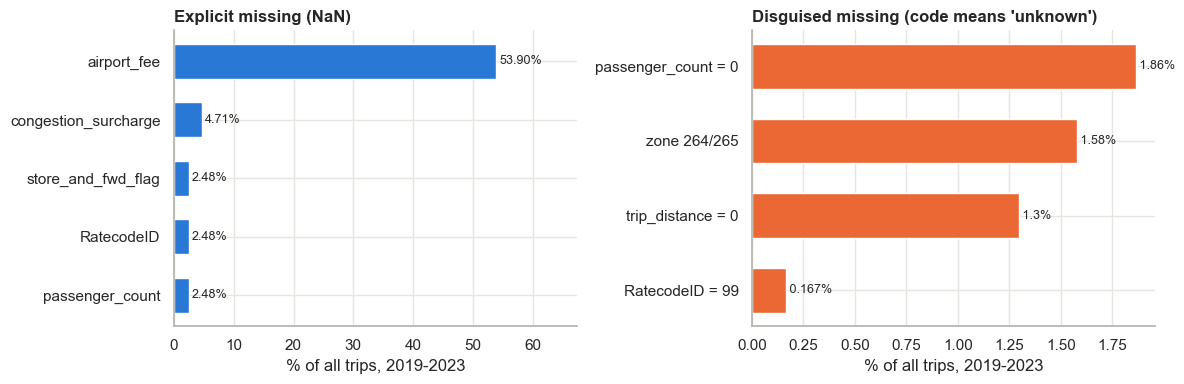

In [33]:
disguised = (sanity.loc[["passenger_count = 0", "trip_distance = 0", "pickup or dropoff zone 264/265 (unknown)",
                         "RatecodeID = 99 (unknown)"], "% of trips"]
             .rename({"pickup or dropoff zone 264/265 (unknown)": "zone 264/265", "RatecodeID = 99 (unknown)": "RatecodeID = 99"}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
m = missing["% missing"].sort_values()
axes[0].barh(m.index, m.values, color=BLUE, height=0.6)
axes[0].set(title="Explicit missing (NaN)", xlabel=f"% of all trips, {YEARS[0]}-{YEARS[-1]}", xlim=(0, max(m.max() * 1.25, 1)))
for i, v in enumerate(m.values): axes[0].text(v + m.max() * 0.01, i, f"{v:.2f}%", va="center", fontsize=9)
d = disguised.sort_values()
axes[1].barh(d.index, d.values, color=ORANGE, height=0.6)
axes[1].set(title="Disguised missing (code means 'unknown')", xlabel=f"% of all trips, {YEARS[0]}-{YEARS[-1]}")
for i, v in enumerate(d.values): axes[1].text(v, i, f" {v:.3g}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

`airport_fee` is empty for 2019, 2020 and early 2021 because the fee did not exist yet; after that it is missing only on rows without a meter record, like `passenger_count`, `RatecodeID`, `store_and_fwd_flag` and (after January 2019) `congestion_surcharge`.

### 8.2 The target: distribution of `fare_amount`

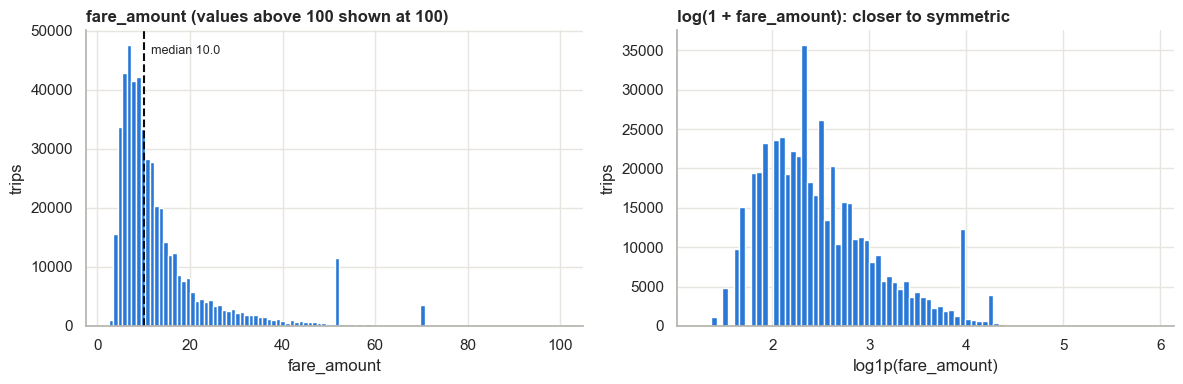

skewness: raw 2.76 | log1p 0.86
trips at exactly $52: 2.26%
trips at exactly $70: 0.70%


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sample[TARGET].clip(upper=100), bins=100, color=BLUE)
axes[0].axvline(sample[TARGET].median(), color="#0b0b0b", lw=1.5, ls="--")
axes[0].text(sample[TARGET].median(), axes[0].get_ylim()[1] * 0.92, f"  median {sample[TARGET].median():.1f}", fontsize=9)
axes[0].set(title=f"{TARGET} (values above 100 shown at 100)", xlabel=TARGET, ylabel="trips")
axes[1].hist(np.log1p(sample[TARGET]), bins=80, color=BLUE)
axes[1].set(title=f"log(1 + {TARGET}): closer to symmetric", xlabel=f"log1p({TARGET})", ylabel="trips")
plt.tight_layout(); plt.show()
print(f"skewness: raw {sample[TARGET].skew():.2f} | log1p {np.log1p(sample[TARGET]).skew():.2f}")
for v in [52, 70]:
    print(f"trips at exactly ${v}: {np.mean(np.isclose(sample[TARGET], v)) * 100:.2f}%")

The target is strongly right-skewed (skewness 2.76): most trips are short and cheap (median $10.00 over the five years), with a long tail of airport and long-distance trips. There are **two** flat-fare spikes: $52, the JFK fare until 18 December 2022 (2.3% of sampled trips), and $70 after it (0.7%). For models sensitive to skew (linear regression), training on `log1p(fare)` (skewness 0.86) and converting back with `expm1` often helps.

### 8.3 Fare vs distance: the strongest relationship, before and after the fare increase

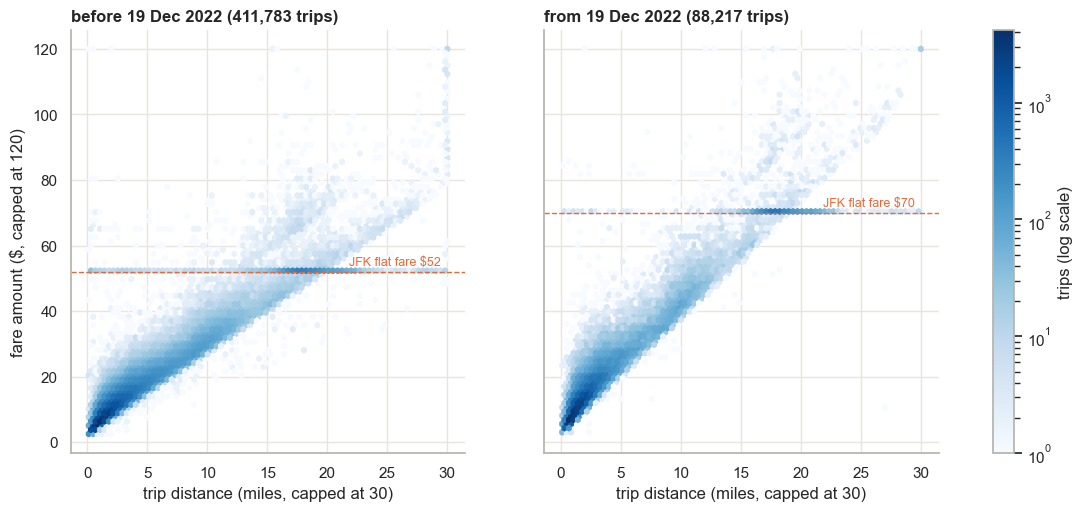

before: median fare per mile 4.26 $/mi
after : median fare per mile 5.90 $/mi


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, (label, d, jfk_fare) in zip(axes, [("before 19 Dec 2022", sample[sample.new_tariff == 0], 52),
                                           ("from 19 Dec 2022", sample[sample.new_tariff == 1], 70)]):
    hb = ax.hexbin(d.trip_distance.clip(upper=30), d.fare_amount.clip(upper=120),
                   gridsize=80, bins="log", cmap="Blues", mincnt=1)
    ax.axhline(jfk_fare, color=ORANGE, lw=1, ls="--")
    ax.text(29.5, jfk_fare + 2, f"JFK flat fare ${jfk_fare}", color=ORANGE, ha="right", fontsize=9)
    ax.set(title=f"{label} ({len(d):,} trips)", xlabel="trip distance (miles, capped at 30)")
axes[0].set_ylabel("fare amount ($, capped at 120)")
fig.colorbar(hb, ax=list(axes), label="trips (log scale)")
plt.show()

# Typical price per mile in each period (median fare / distance, standard trips of 2-10 miles)
for label, d in [("before", sample[sample.new_tariff == 0]), ("after", sample[sample.new_tariff == 1])]:
    s = d[(d.RatecodeID == 1) & d.trip_distance.between(2, 10)]
    print(f"{label:6s}: median fare per mile {np.median(s.fare_amount / s.trip_distance):.2f} $/mi")

Both periods show a tight diagonal band, the meter rate, and a horizontal line, the JFK flat fare: $52 before 19 December 2022 and $70 after. The band after the increase is steeper: the median fare per mile of standard 2–10-mile trips rose from $4.26 to $5.90 (+38%). A model that doesn't know which period a trip is from sees two overlapping bands, which is why section 5.4 converts every fare to one price list. Points far from the bands are the remaining noise: negotiated fares, traffic-heavy trips and meter quirks.

### 8.4 When do people ride? (all trips, 2019–2023)

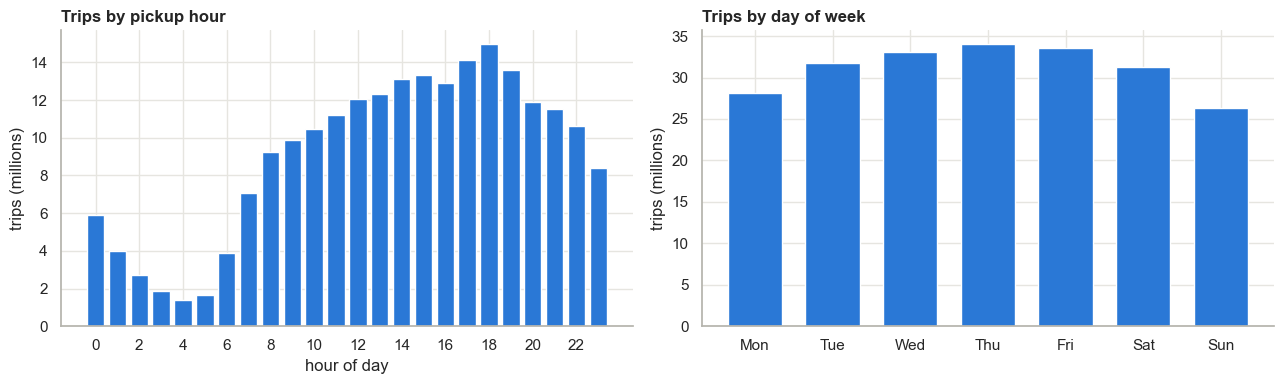

CPU times: user 8.7 s, sys: 536 ms, total: 9.24 s
Wall time: 1.67 s


In [37]:
%%time
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hd = sql(f'''
    SELECT isodow(tpep_pickup_datetime) - 1 AS dow, hour(tpep_pickup_datetime) AS hour, count(*) AS trips
    FROM all_trips WHERE year(tpep_pickup_datetime) BETWEEN {YEARS[0]} AND {YEARS[-1]}
    GROUP BY ALL
''')
heat = hd.pivot(index="dow", columns="hour", values="trips").sort_index()
heat.index = dow_names

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour = heat.sum(axis=0)
axes[0].bar(by_hour.index, by_hour.values / 1e6, color=BLUE, width=0.8)
axes[0].set(title="Trips by pickup hour", xlabel="hour of day", ylabel="trips (millions)", xticks=range(0, 24, 2))
by_dow = heat.sum(axis=1)
axes[1].bar(by_dow.index, by_dow.values / 1e6, color=BLUE, width=0.7)
axes[1].set(title="Trips by day of week", ylabel="trips (millions)")
plt.tight_layout(); plt.show()

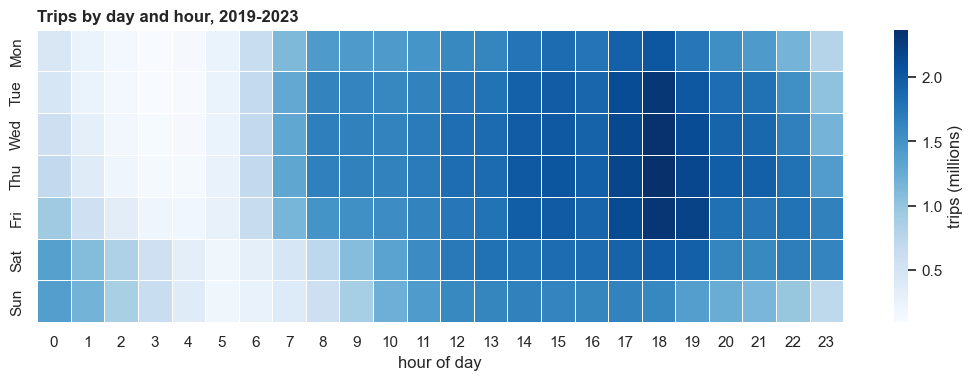

In [38]:
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat / 1e6, cmap="Blues", ax=ax, cbar_kws={"label": "trips (millions)"}, linewidths=0.5, linecolor="white")
ax.set(title=f"Trips by day and hour, {YEARS[0]}-{YEARS[-1]}", xlabel="hour of day", ylabel=""); ax.grid(False)
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

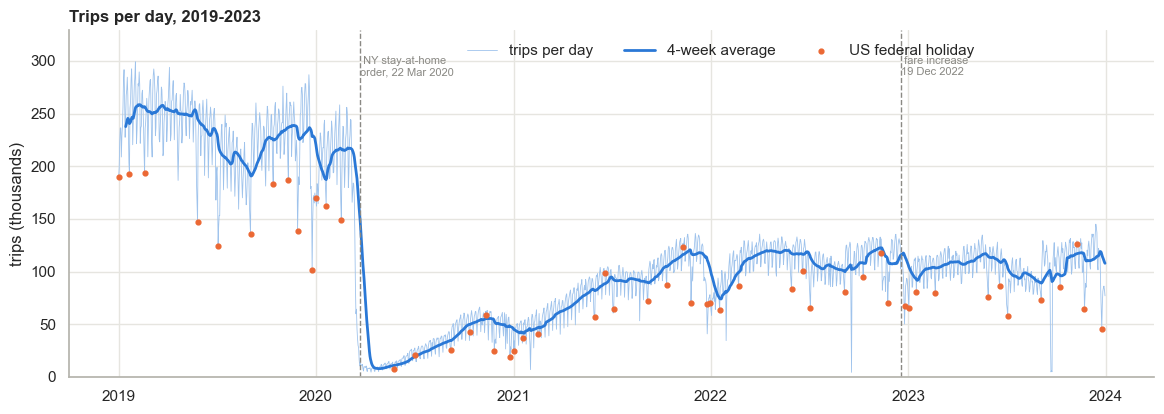

,days with data,average trips per day,quietest day,trips on quietest day,busiest day,trips on busiest day
year,,,,,,
2019,365,231762,Wed 25 Dec,101911,Fri 01 Feb,299198
2020,366,67343,Sun 12 Apr,4432,Fri 14 Feb,258277
2021,365,84665,Mon 01 Feb,6803,Fri 03 Dec,136231
2022,365,108643,Sun 18 Sep,4229,Fri 01 Apr,135547
2023,365,104958,Fri 22 Sep,4633,Thu 14 Dec,144978


Days with under a quarter of the trips of the surrounding fortnight:
Mon 01 Feb 2021 (6,803), Sun 18 Sep 2022 (4,229), Fri 22 Sep 2023 (4,633), Sat 23 Sep 2023 (5,732), Sun 24 Sep 2023 (4,813)


In [39]:
from pandas.tseries.holiday import USFederalHolidayCalendar

daily = sql(f'''
    SELECT CAST(tpep_pickup_datetime AS DATE) AS day, count(*) AS trips
    FROM all_trips
    WHERE year(tpep_pickup_datetime) BETWEEN {YEARS[0]} AND {YEARS[-1]}
      AND strftime(tpep_pickup_datetime, '%Y-%m') = file_month      -- ignore trips with a wrong date
    GROUP BY 1 ORDER BY 1
''').set_index("day").trips
daily.index = pd.to_datetime(daily.index)
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"))   # missing file -> gap
holidays = USFederalHolidayCalendar().holidays(start=daily.index.min(), end=daily.index.max())

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily.index, daily.values / 1e3, color="#9fc3ec", lw=0.6, label="trips per day")
ax.plot(daily.index, daily.rolling(28, min_periods=14).mean() / 1e3, color=BLUE, lw=2, label="4-week average")
h = daily[daily.index.isin(holidays)]
ax.scatter(h.index, h.values / 1e3, color=ORANGE, s=12, zorder=3, label="US federal holiday")
for day, text in [(pd.Timestamp(2020, 3, 22), "NY stay-at-home\norder, 22 Mar 2020"),
                  (TARIFF_CHANGE, "fare increase\n19 Dec 2022")]:
    ax.axvline(day, color=GREY, lw=1, ls="--")
    ax.text(day, daily.max() / 1e3 * 1.02, " " + text, fontsize=8, color=GREY, va="top")
for gap in daily[daily.isna()].index.to_period("M").unique():
    ax.axvspan(gap.start_time, gap.end_time, color="#eeeeea", zorder=0)
    ax.text(gap.start_time, daily.max() / 1e3 * 0.55, " no file\n " + gap.strftime("%b %Y"), fontsize=8, color=GREY)
ax.set(title=f"Trips per day, {YEARS[0]}-{YEARS[-1]}", ylabel="trips (thousands)", ylim=(0, daily.max() / 1e3 * 1.1))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.6, 1.0), ncol=3)
plt.show()

d = daily.dropna().astype("int64")
by_year_days = pd.DataFrame({
    "days with data": d.groupby(d.index.year).size(),
    "average trips per day": d.groupby(d.index.year).mean().round().astype("int64"),
    "quietest day": d.groupby(d.index.year).idxmin().dt.strftime("%a %d %b"),
    "trips on quietest day": d.groupby(d.index.year).min(),
    "busiest day": d.groupby(d.index.year).idxmax().dt.strftime("%a %d %b"),
    "trips on busiest day": d.groupby(d.index.year).max()}).rename_axis("year")
display(by_year_days)

# Whole days on which the files hold far fewer trips than the days around them
typical = d.rolling(15, center=True, min_periods=5).median()
odd = d[d < 0.25 * typical]
print("Days with under a quarter of the trips of the surrounding fortnight:")
print(", ".join(f"{day:%a %d %b %Y} ({n:,})" for day, n in odd.items()))

**What five years show**
- **Hours:** demand peaks at 6 pm (14.9 million trips started at 18:00 over the five years) and is lowest at 4–5 am (1.4 million at 04:00).
- **Weekdays:** Thursday is the busiest day (34.0 million trips) and Sunday the quietest (26.3 million).
- **COVID:** after New York's stay-at-home order of 22 March 2020, trips fell from about 200,000 a day to 4,400–10,300 a day in April 2020 (7,900 on average; the low was Sunday 12 April, 4,432 trips). By 2022–2023 volume had recovered to about 105,000–109,000 a day, under half of 2019's 232,000.
- **Holidays and storms:** Christmas Day is 2019's quietest day (101,911 trips), and Monday 1 February 2021 (6,803 trips) was a major snowstorm.
- **Gaps in the files:** Sunday 18 September 2022 (4,229 trips) and 22–24 September 2023 (4,600–5,700 a day) are not real quiet days. Their trips are thin in every hour of the day, so most of their records are missing from the published files.

These patterns are a strong argument for the time features (hour, day of week, month) and for time-ordered validation.

### 8.5 How the target varies by time and rate code

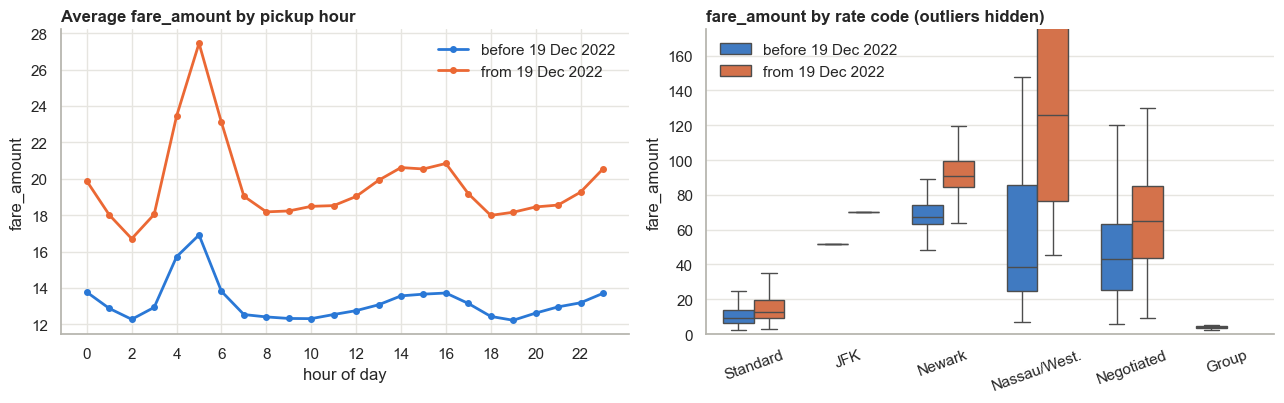

pickup_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
before 19 Dec 2022,13.770,12.880,12.280,12.930,15.720,16.910,13.810,12.540,12.410,12.320,12.310,12.540,12.750,13.070,13.570,13.660,13.720,13.150,12.440,12.230,12.620,12.960,13.190,13.700
from 19 Dec 2022,19.870,18.010,16.710,18.040,23.440,27.440,23.100,19.040,18.180,18.230,18.480,18.520,19.030,19.910,20.620,20.540,20.840,19.180,17.990,18.160,18.450,18.560,19.260,20.540


In [40]:
period = pd.Series(np.where(df.new_tariff == 1, "from 19 Dec 2022", "before 19 Dec 2022"), index=df.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
avg = df.groupby([period, df.pickup_hour])[TARGET].mean().unstack(0)
for col, colour in [("before 19 Dec 2022", BLUE), ("from 19 Dec 2022", ORANGE)]:
    axes[0].plot(avg.index, avg[col], color=colour, lw=2, marker="o", ms=4, label=col)
axes[0].set(title=f"Average {TARGET} by pickup hour", xlabel="hour of day", ylabel=TARGET, xticks=range(0, 24, 2))
axes[0].legend(frameon=False)
rate_names = {1: "Standard", 2: "JFK", 3: "Newark", 4: "Nassau/West.", 5: "Negotiated", 6: "Group"}
order = [r for r in rate_names if r in sample.RatecodeID.unique()]
s2 = sample.assign(period=np.where(sample.new_tariff == 1, "from 19 Dec 2022", "before 19 Dec 2022"))
sns.boxplot(data=s2, x="RatecodeID", y=TARGET, order=order, hue="period",
            hue_order=["before 19 Dec 2022", "from 19 Dec 2022"], palette=[BLUE, ORANGE],
            fliersize=0, width=0.65, ax=axes[1], linewidth=1)
axes[1].set_xticks(range(len(order)))
axes[1].set_xticklabels([rate_names[r] for r in order], rotation=20)
axes[1].set(title=f"{TARGET} by rate code (outliers hidden)", xlabel="", ylim=(0, 175 if TARGET == "fare_amount" else None))
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
avg.round(2).T

Fares are about 50% higher at most hours after the increase (36–67% depending on the hour: the new prices, plus somewhat longer trips in 2023), but the shape is the same. Trips starting at 4–6 am have the highest average fare ($16.91 at 5 am before, $27.44 after) because they are longer: early airport runs. Much of the hour effect is really a distance effect, but hour still helps the model with traffic. Rate code separates fares sharply, and the JFK box is a single flat value in each period ($52, then $70), confirming that rate code is a key feature and that the model must know which price list applies.

### 8.6 Payment type and tips (why cash tips can't be modelled)

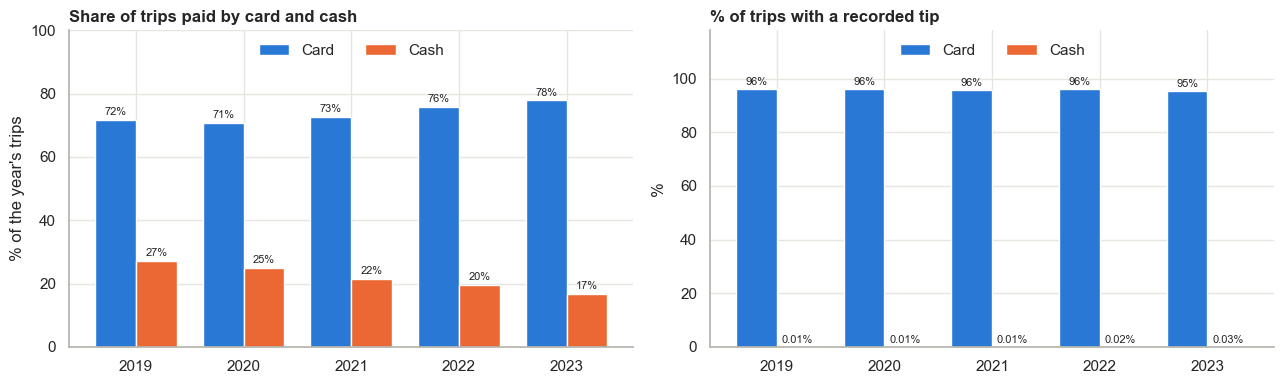

payment,Card,Cash,Dispute,No charge,No record,Unknown
year,,,,,,
2019,71.660,27.070,0.220,0.530,0.530,0.000
2020,70.850,24.940,0.330,0.590,3.290,0.000
2021,72.740,21.580,0.390,0.500,4.780,0.000
2022,75.870,19.580,0.620,0.490,3.450,0.000
2023,77.930,16.720,1.300,0.630,3.420,0.000


In [41]:
pay_names = {0: "No record", 1: "Card", 2: "Cash", 3: "No charge", 4: "Dispute", 5: "Unknown", 6: "Voided"}
p = sql('''
    SELECT substr(file_month, 1, 4) AS year, payment_type, count(*) AS trips,
           100 * avg(CASE WHEN tip_amount > 0 THEN 1 ELSE 0 END) AS tip_rate
    FROM all_trips GROUP BY ALL
''')
p["payment"] = p.payment_type.map(pay_names)
share = p.pivot_table(index="year", columns="payment", values="trips", aggfunc="sum")
share = share.div(share.sum(axis=1), axis=0) * 100
tips = p.pivot_table(index="year", columns="payment", values="tip_rate")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(share.index)); width = 0.38
for k, (col, colour) in enumerate([("Card", BLUE), ("Cash", ORANGE)]):
    axes[0].bar(x + (k - 0.5) * width, share[col], width=width, color=colour, label=col)
    axes[1].bar(x + (k - 0.5) * width, tips[col], width=width, color=colour, label=col)
    for i, v in enumerate(share[col]): axes[0].text(i + (k - 0.5) * width, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8)
    for i, v in enumerate(tips[col]):
        axes[1].text(i + (k - 0.5) * width, v + 1.5, f"{v:.0f}%" if v >= 1 else f"{v:.2f}%", ha="center", fontsize=8)
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(share.index); ax.legend(frameon=False, loc="upper center", ncol=2)
axes[0].set(title="Share of trips paid by card and cash", ylabel="% of the year's trips", ylim=(0, 100))
axes[1].set(title="% of trips with a recorded tip", ylabel="%", ylim=(0, 118))
plt.tight_layout(); plt.show()
share.round(2)

Card payments grew from 71.7% of trips in 2019 to 77.9% in 2023, and cash fell from 27.1% to 16.7%. 95–96% of card trips record a tip in every year, against 0.01–0.03% of cash trips, because cash tips aren't captured. A tipping model would therefore have to use card trips only. Disputed payments also grew, from 0.22% to 1.30% of trips.

### 8.7 Busiest pickup zones

zone names from https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv


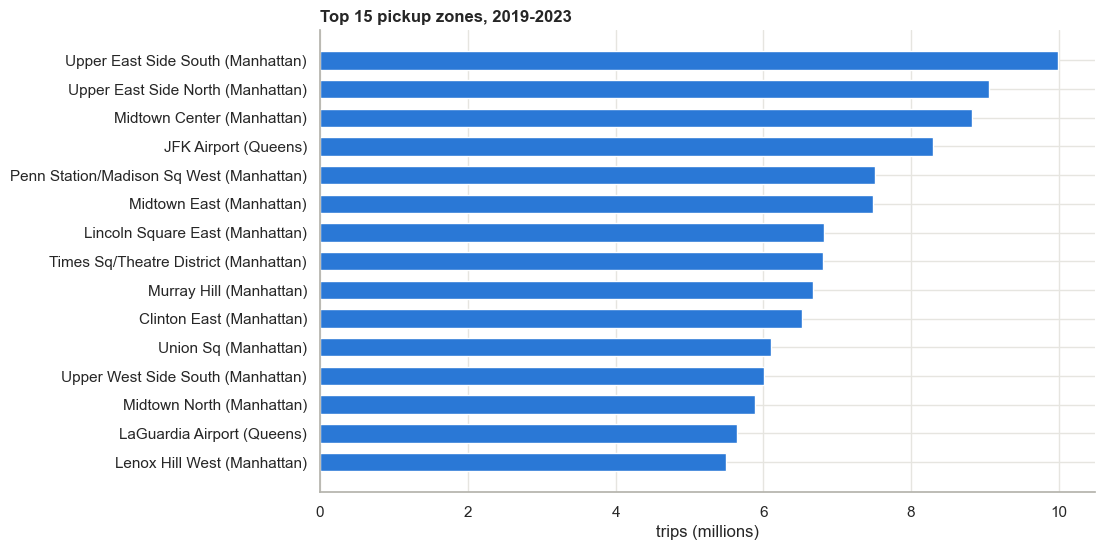

In [42]:
# Zone names come from the TLC lookup table. Tries a local copy first, then the TLC website.
ZONE_SOURCES = [DATA_DIR / "taxi_zone_lookup.csv",                                                  # local copy
                "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",                     # TLC website
                "https://github.com/DataTalksClub/nyc-tlc-data/releases/download/misc/taxi_zone_lookup.csv"]  # mirror
zone_name = pd.Series(dtype=str)
for src in ZONE_SOURCES:
    if isinstance(src, Path) and not src.exists():
        continue
    try:
        zones = pd.read_csv(src)
        zone_name = zones.set_index("LocationID").apply(lambda r: f"{r.Zone} ({r.Borough})", axis=1)
        print(f"zone names from {src}")
        break
    except Exception as e:
        print(f"zone lookup not available from {src}: {e}")
if zone_name.empty:
    print("showing zone IDs instead of names")

top = sql("SELECT PULocationID, count(*) AS trips FROM all_trips GROUP BY 1 ORDER BY trips DESC LIMIT 15")
top = top.iloc[::-1]
labels = [zone_name.get(i, f"Zone {i}") for i in top.PULocationID]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, top.trips / 1e6, color=BLUE, height=0.65)
ax.set(title=f"Top 15 pickup zones, {YEARS[0]}-{YEARS[-1]}", xlabel="trips (millions)")
plt.show()

### 8.8 Correlation between numeric variables

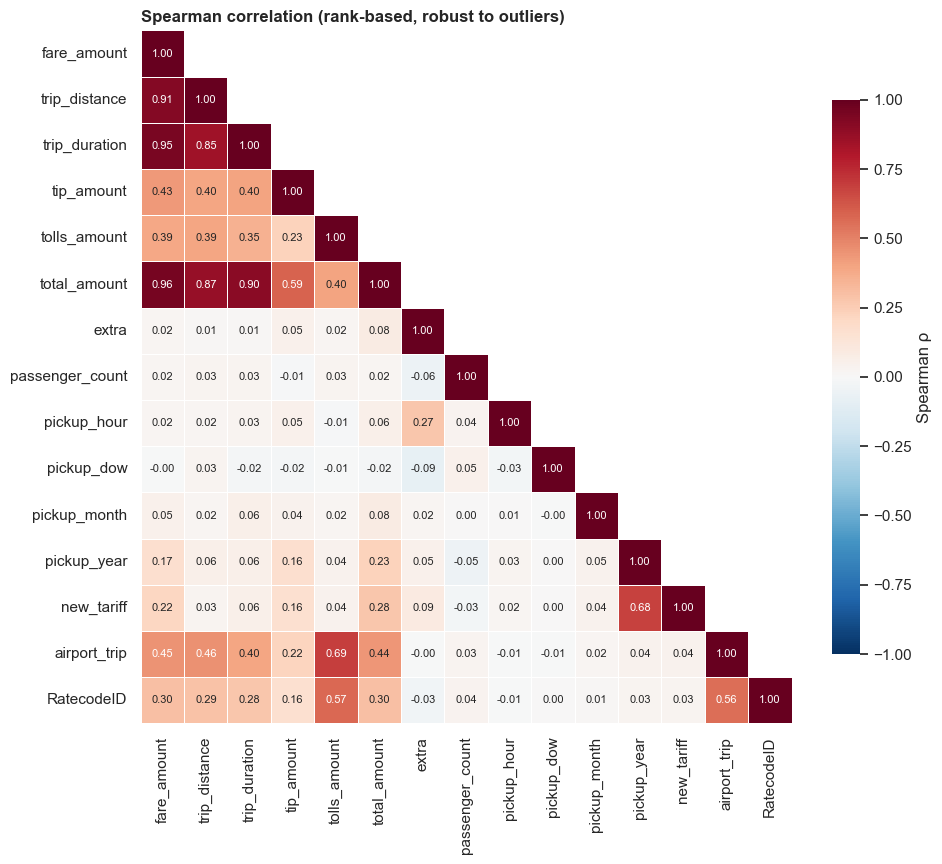

In [43]:
show = ["fare_amount", "trip_distance", "trip_duration", "tip_amount", "tolls_amount", "total_amount",
        "extra", "passenger_count", "pickup_hour", "pickup_dow", "pickup_month", "pickup_year", "new_tariff",
        "airport_trip", "RatecodeID"]
c = sample[[s for s in show if s in sample]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10.5, 9))
sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool), k=1), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Spearman ρ", "shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation (rank-based, robust to outliers)"); ax.grid(False)
plt.show()

`fare_amount` correlates very strongly with `trip_distance` (ρ 0.915, the legitimate driver), but also with `trip_duration`, `tolls_amount` and `total_amount`. Those are the leakage columns identified in section 6, which is exactly why they are excluded from the features. `new_tariff` (0.215) and `pickup_year` (0.167) correlate with the fare because of the December 2022 increase; once fares are converted to 2023 prices the models no longer need them (section 10.2). `pickup_month` hardly correlates at all (0.05).

## 9. Year by year: what changes from 2019 to 2023

Sections 1–8 looked at all five years at once. This section asks how things **change from month to month and year to year**, which matters for the models: they are trained on earlier months and tested on later ones. It ends with the train/validation/test split used in section 10.

### 9.1 Monthly summary of every trip

One DuckDB query over the `all_trips` view from section 1.4, one row per monthly file. `file_month` comes from each row's source file, so trips with a wrong pickup date (bad meter clocks) are still counted in the month whose file they came from. Months without a file show as gaps in the charts.

In [44]:
%%time
monthly = sql('''
    SELECT file_month,
           count(*)                                                                     AS trips,
           sum(CASE WHEN strftime(tpep_pickup_datetime, '%Y-%m') <> file_month THEN 1 ELSE 0 END)
                                                                                        AS pickup_outside_month,
           100 * avg(CASE WHEN passenger_count IS NULL THEN 1 ELSE 0 END)               AS pct_no_meter_record,
           100 * avg(CASE WHEN congestion_surcharge > 0 THEN 1 ELSE 0 END)              AS pct_congestion_charged,
           100 * avg(CASE WHEN airport_fee > 0 THEN 1 ELSE 0 END)                       AS pct_airport_fee_charged,
           median(fare_amount)  FILTER (WHERE fare_amount BETWEEN 2.5 AND 500)          AS median_fare,
           avg(trip_distance)   FILTER (WHERE trip_distance BETWEEN 0.1 AND 100)        AS avg_distance_mi
    FROM all_trips
    GROUP BY file_month
    ORDER BY file_month
''').set_index("file_month")
monthly.index = pd.to_datetime(monthly.index + "-01")
monthly.round(2)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 33.4 s, sys: 3.4 s, total: 36.8 s
Wall time: 7.72 s


,trips,pickup_outside_month,pct_no_meter_record,pct_congestion_charged,pct_airport_fee_charged,median_fare,avg_distance_mi
file_month,,,,,,,
2019-01-01,7696617,537.000,0.370,0.000,0.000,9.000,2.860
2019-02-01,7049370,626.000,0.420,86.700,0.000,9.000,2.940
2019-03-01,7866620,510.000,0.430,90.950,0.000,9.500,3.050
2019-04-01,7475949,313.000,0.570,91.250,0.000,9.500,3.070
2019-05-01,7598445,377.000,0.430,91.200,0.000,9.500,3.090
2019-06-01,6971560,534.000,0.440,90.730,0.000,9.500,3.140
2019-07-01,6310419,285.000,0.540,90.560,0.000,9.500,3.150
2019-08-01,6073357,506.000,0.550,90.340,0.000,9.500,3.210
2019-09-01,6567788,392.000,0.520,91.190,0.000,10.000,3.130


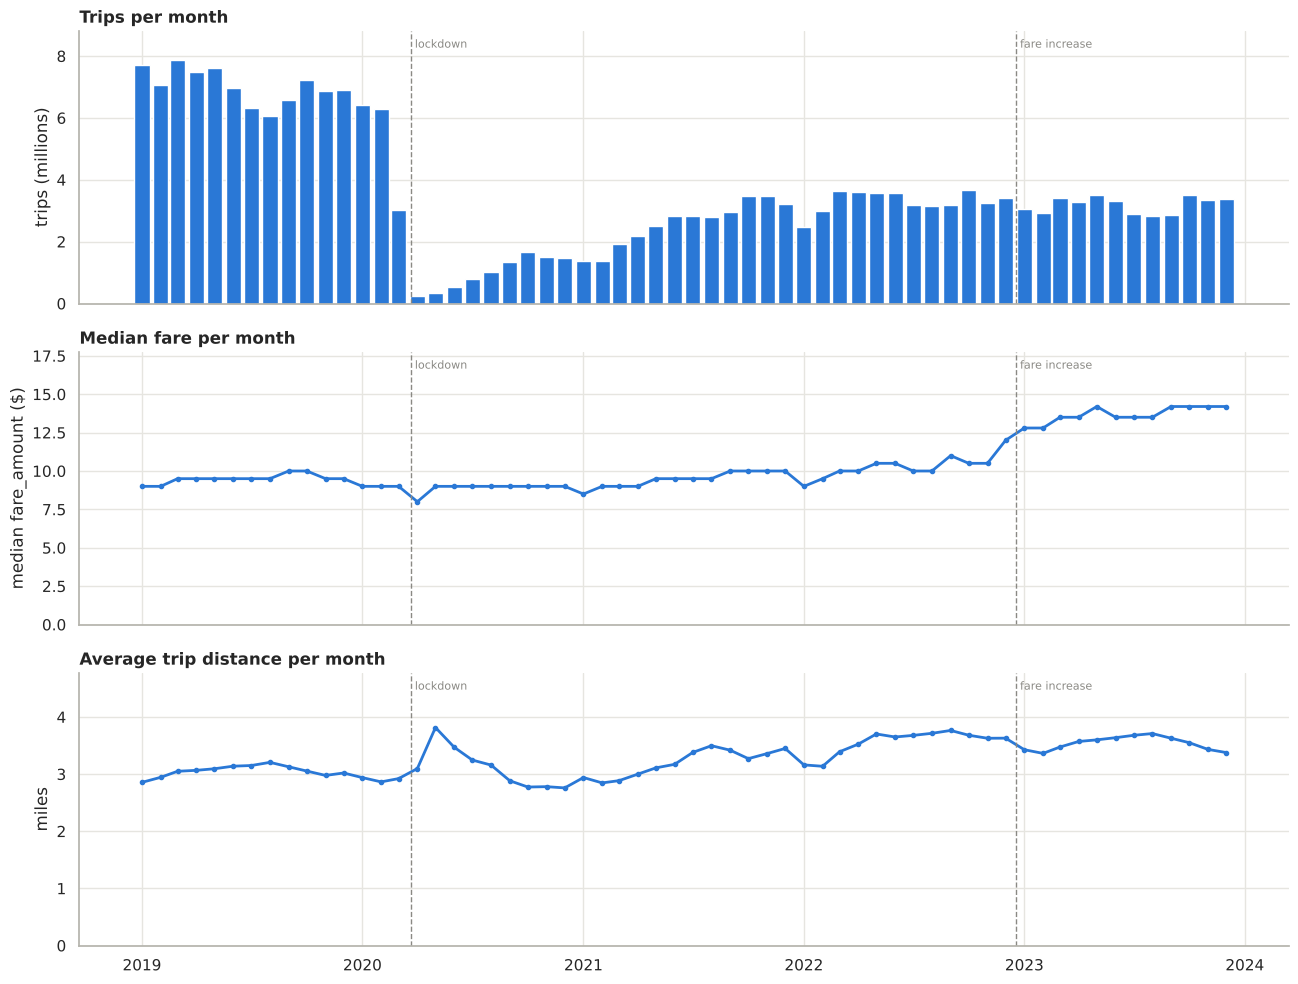

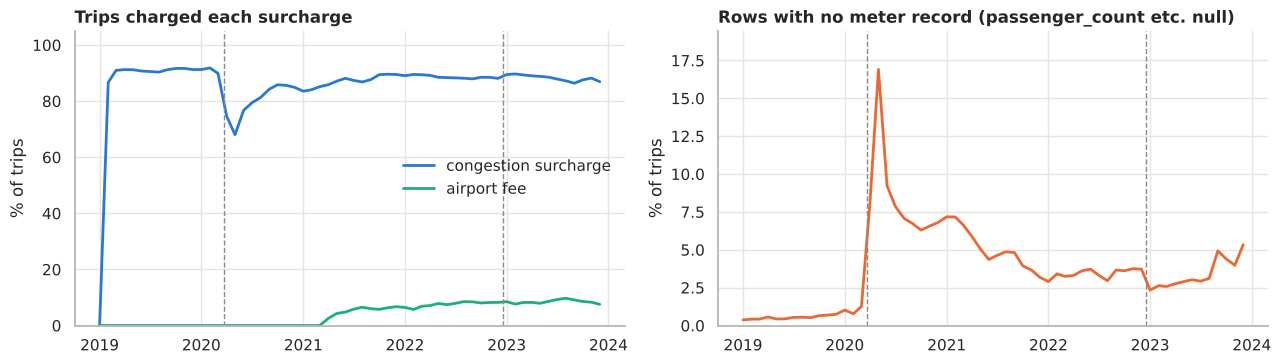

In [45]:
m = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS"))   # missing file -> gap
LOCKDOWN = pd.Timestamp(2020, 3, 22)

def mark_events(ax, label=False):
    for day, text in [(LOCKDOWN, "lockdown"), (TARIFF_CHANGE, "fare increase")]:
        ax.axvline(day, color=GREY, lw=1, ls="--")
        if label:
            ax.text(day, ax.get_ylim()[1] * 0.97, " " + text, fontsize=8, color=GREY, va="top")

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axes[0].bar(m.index, m.trips / 1e6, width=25, color=BLUE)
axes[0].set(title="Trips per month", ylabel="trips (millions)", ylim=(0, m.trips.max() / 1e6 * 1.12))
for d in m.index[m.trips.isna()]:
    axes[0].text(d + pd.Timedelta(days=12), 0.6, d.strftime("%b %Y") + "\nno file", ha="left", fontsize=8, color=GREY)
axes[1].plot(m.index, m.median_fare, color=BLUE, lw=2, marker="o", ms=3)
axes[1].set(title="Median fare per month", ylabel="median fare_amount ($)", ylim=(0, m.median_fare.max() * 1.25))
axes[2].plot(m.index, m.avg_distance_mi, color=BLUE, lw=2, marker="o", ms=3)
axes[2].set(title="Average trip distance per month", ylabel="miles", ylim=(0, m.avg_distance_mi.max() * 1.25))
for ax in axes: mark_events(ax, label=True)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(m.index, m.pct_congestion_charged, color=BLUE, lw=2, label="congestion surcharge")
axes[0].plot(m.index, m.pct_airport_fee_charged, color=AQUA, lw=2, label="airport fee")
axes[0].set(title="Trips charged each surcharge", ylabel="% of trips", ylim=(0, 105))
axes[0].legend(frameon=False, loc="center right")
axes[1].plot(m.index, m.pct_no_meter_record, color=ORANGE, lw=2)
axes[1].set(title="Rows with no meter record (passenger_count etc. null)", ylabel="% of trips",
            ylim=(0, m.pct_no_meter_record.max() * 1.15))
for ax in axes: mark_events(ax)
plt.tight_layout(); plt.show()

In [45]:
# One row per year: exact counts from DuckDB, medians from the 1% sample
yearly = sql('''
    SELECT CAST(substr(file_month, 1, 4) AS INTEGER) AS year, count(DISTINCT file_month) AS months, count(*) AS trips,
           CAST(count(*) / count(DISTINCT file_month) AS BIGINT)                        AS trips_per_month,
           100 * avg(CASE WHEN passenger_count IS NULL THEN 1 ELSE 0 END)               AS pct_no_meter_record,
           avg(trip_distance) FILTER (WHERE trip_distance BETWEEN 0.1 AND 100)          AS avg_distance_mi
    FROM all_trips GROUP BY 1 ORDER BY 1
''').set_index("year")
yearly["median fare (sample)"] = trips.groupby("pickup_year").fare_amount.median()
yearly["median fare in 2023 prices (sample)"] = trips.groupby("pickup_year").fare_2023.median()
yearly.round(2)

,months,trips,trips_per_month,pct_no_meter_record,avg_distance_mi,median fare (sample),median fare in 2023 prices (sample)
year,,,,,,,
2019,12,84598444,7049870,0.530,3.050,9.500,12.800
2020,12,24649092,2054091,3.290,2.930,9.000,12.100
2021,12,30904308,2575359,4.780,3.250,9.500,12.800
2022,12,39656098,3304675,3.450,3.570,10.000,13.500
2023,12,38310226,3192519,3.420,3.540,13.500,13.500


**What five years show**
- **Volume collapsed with COVID and only partly recovered:** 6.1–7.9 million trips a month in 2019, 3.0 million in March 2020, only 238,073 in April 2020 (96% below February 2020), and 2.5–3.7 million a month in 2022–2023.
- **The median fare was flat at $8.00–$10.00 from 2019 to spring 2022** (lowest in April 2020), crept up to $10.00–$11.00 during 2022 as trips got longer, then jumped with the fare increase: $12.00 in December 2022 (13 days at the new prices), $12.80 in January 2023 and $13.50–$14.20 for the rest of 2023.
- **Trips got longer:** the average distance rose from 2.86–3.21 miles a month in 2019 to 3.4–3.8 miles in most months of 2022–2023.
- **The congestion surcharge** starts in February 2019 (0% of January trips, 87% of February trips) and covers about 91% of trips for the rest of 2019. It fell to 68% in May 2020 and has been 84–90% since 2021. **The airport fee** appears in April 2021 and reaches about 8–10% of trips in 2023.
- **Data quality varies a lot:** rows with no meter record were 0.4–0.7% of trips in 2019, 17% in May 2020, 3–7% in 2021 and 2–5% in 2022–2023. Every file has some trips dated outside its month (285–648 a month in 2019, mostly under 200 afterwards).

The yearly table puts this in one place, and its last column confirms that converting old fares to 2023 prices (section 5.4) removes the price jump: the median fare in 2023 prices is $12.10–$13.50 in every year.

### 9.2 Cleaning, year by year

The same `clean_trips` rules from section 5.1 were applied to every month's sample in section 5.3. This table shows the share each rule removed, by year.

In [46]:
# Cleaning by year: % of sampled rows removed by each rule
by_year = removed.groupby(removed.index.str[:4]).sum()
removed_pct = by_year.drop(columns=["rows kept"]).div(by_year["rows kept"] + by_year["TOTAL removed"], axis=0) * 100
removed_pct.columns = [c.replace(" (refund)", "") for c in removed_pct.columns]
removed_pct.round(2).rename_axis("year")

,pickup outside month,incomplete meter record,duration not in 1-180 min,distance not in 0.1-100 mi,fare not in $2.50-$500,unknown rate code,unknown zone,avg speed not in 0.5-80 mph,negative charge,TOTAL removed
year,,,,,,,,,,
2019,0.010,0.540,1.280,0.320,0.150,0.000,1.100,0.010,0.000,3.410
2020,0.010,3.290,1.230,0.720,0.300,0.000,0.820,0.010,0.000,6.370
2021,0.010,4.770,1.210,0.650,0.350,0.020,1.070,0.020,0.000,8.110
2022,0.000,3.430,1.410,0.490,0.480,0.270,1.510,0.010,0.000,7.610
2023,0.000,3.410,1.230,0.580,0.810,0.490,1.390,0.010,0.000,7.930


Cleaning removes 3.4% of sampled trips in 2019 but 6.4–8.1% in 2020–2023. Most of the difference is the rows with no meter record (0.54% in 2019, 3.3–4.8% later). Invalid fares (0.15% → 0.81%) and unknown rate codes (0% → 0.49%) also become more common. Because one shared function cleans every month, these differences come from the data, not from different rules.

### 9.3 What changes over the years: traffic

Fares are charged by distance **and** by time spent slow or stopped in traffic. When traffic is slower, two trips of the same distance can have quite different fares, which makes the fare harder to predict from distance alone. The charts compare, for each month, the median speed of standard-rate trips and how much the fares of similar-length trips (1.5–2.5 miles) spread out. The spread is measured on `fare_2023`, so the price increase itself doesn't count as "spread".

NameError: name 'mark_events' is not defined

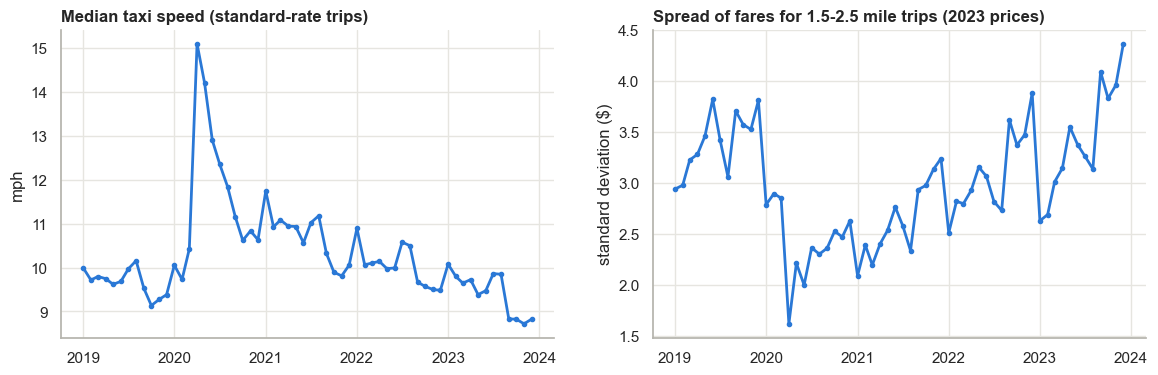

In [47]:
std_rate = trips[trips.RatecodeID == 1].assign(speed=lambda d: d.trip_distance / (d.trip_duration / 60))
two = std_rate[std_rate.trip_distance.between(1.5, 2.5)]
by_month = pd.DataFrame({
    "median speed (mph)": std_rate.groupby(["pickup_year", "pickup_month"]).speed.median(),
    "fare spread, 1.5-2.5 mi trips ($ SD, 2023 prices)": two.groupby(["pickup_year", "pickup_month"]).fare_2023.std(),
})
by_month.index = pd.to_datetime([f"{y}-{mo:02d}-01" for y, mo in by_month.index])
bm = by_month.reindex(pd.date_range(by_month.index.min(), by_month.index.max(), freq="MS"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(bm.index, bm.iloc[:, 0], color=BLUE, lw=2, marker="o", ms=3)
axes[0].set(title="Median taxi speed (standard-rate trips)", ylabel="mph")
axes[1].plot(bm.index, bm.iloc[:, 1], color=BLUE, lw=2, marker="o", ms=3)
axes[1].set(title="Spread of fares for 1.5-2.5 mile trips (2023 prices)", ylabel="standard deviation ($)")
for ax in axes: mark_events(ax, label=True)
plt.tight_layout(); plt.show()

speed_by_year = by_month.groupby(by_month.index.year).mean().round(2).rename_axis("year (monthly average)")
display(speed_by_year)
pd.concat([by_month.nlargest(3, "median speed (mph)"), by_month.nsmallest(3, "median speed (mph)")]).round(2)

**Traffic changed more than anything else over the five years.** The median speed of standard-rate trips averaged 9.7 mph in 2019, jumped to 15.1 mph in April 2020 when the streets emptied, and then fell back steadily: 10.7 mph in 2021, 10.0 in 2022 and 9.4 in 2023. **The slowest months of the five years are September–December 2023 (8.7–8.8 mph), which includes the whole test period.**

Slow traffic adds time charges, so the fares of trips of the same length spread out more. In 2023 prices, the spread of 1.5–2.5-mile fares was smallest in spring 2020 ($1.62 in April, $2.00–$2.22 in May–June), about $3.40 on average in 2019 and 2023, and peaked at $3.83–$4.37 in October–December 2023. **The test period is therefore the hardest stretch of the five years to predict**, which is why the test errors in section 10 are higher than the validation errors.

### 9.4 How the five years are split for modelling

Following section 7, the split is **by time**, using whole months:

| Part | Months | Used for |
|---|---|---|
| **Training** | January 2019 – June 2023 | Fitting models during hyper-parameter tuning |
| **Validation** | July – September 2023 | Choosing hyper-parameters and the training set-up (`PredefinedSplit`: fit on training months, score on validation months) |
| **Test** | October – December 2023 | Final score, used **once** per model |

After tuning, each final model is refitted on January 2019 – September 2023, so it learns from the most recent months too, and is then scored on October–December 2023. The test months were never used for any decision.

**Why the last quarter of 2023 and not, say, all of 2023?** The models need to see the new meter prices during training (section 5.4). Holding out a whole year would leave only two weeks of new-price trips in training. Validating and testing on the last two quarters keeps nine months of 2023 in the final training data.

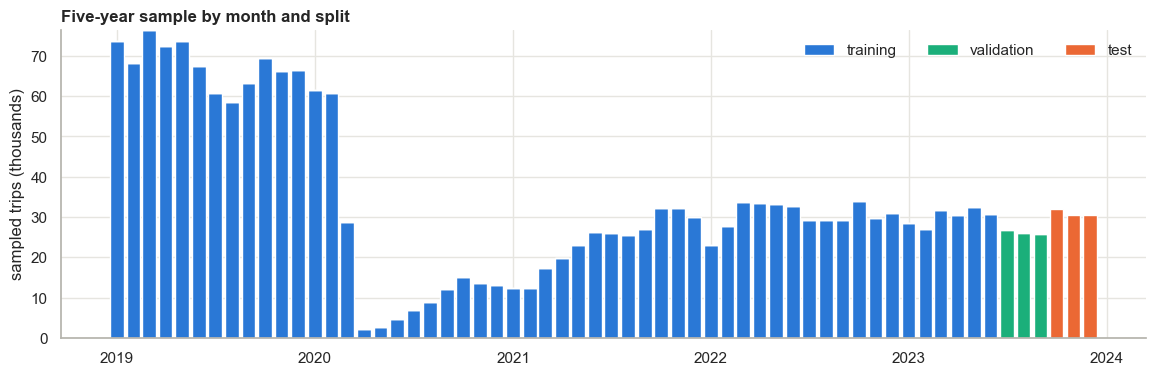

,sampled trips,% of sample
col_0,,
training,1879496,91.600
validation,78497,3.800
test,93033,4.500


In [50]:
TRAIN_END = pd.Timestamp(2023, 7, 1)    # training: before this date (Jan 2019 - Jun 2023)
VALID_END = pd.Timestamp(2023, 10, 1)   # validation: TRAIN_END to VALID_END (Jul-Sep 2023); test: Oct-Dec 2023

part = pd.Series(np.select([trips.tpep_pickup_datetime < TRAIN_END, trips.tpep_pickup_datetime < VALID_END],
                           ["training", "validation"], "test"), index=trips.index)
counts = pd.crosstab([trips.pickup_year, trips.pickup_month], part)[["training", "validation", "test"]]
idx = pd.to_datetime([f"{y}-{mo:02d}-01" for y, mo in counts.index])
fig, ax = plt.subplots(figsize=(14, 4))
bottom = np.zeros(len(counts))
for col, colour in zip(counts.columns, [BLUE, AQUA, ORANGE]):
    ax.bar(idx, counts[col] / 1e3, bottom=bottom, color=colour, width=25, label=col)
    bottom += counts[col].values / 1e3
ax.set(title="Five-year sample by month and split", ylabel="sampled trips (thousands)")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.show()
split_sizes = counts.sum().to_frame("sampled trips")
split_sizes["% of sample"] = (split_sizes["sampled trips"] / split_sizes["sampled trips"].sum() * 100).round(1)
split_sizes

## 10. Modelling: predicting `fare_amount` from five years of trips

Four methods plus two comparison models, all trained and tested on exactly the same data from the five-year sample:

| | Method | Role |
|---|---|---|
| 0 | Predict-the-median, **Linear regression** | Comparison only (baselines to beat) |
| 1 | **Neural network** (multi-layer perceptron) | Required method |
| 2 | **Support vector machine** (SVR, kernel and linear) | Required method |
| 3 | **Random forest** | Substitute method |
| 4 | **Ridge and Lasso regression** | Taught methods (regularised linear models) |

Naive Bayes is not used: it is a classification method and our target is a continuous dollar amount.

**Run time:** about 20 minutes on a typical laptop. The training-size experiment, the SVR and the grid searches are the slow parts.

### 10.1 Set-up: data, features and what "accuracy" means

**Data** (split from section 9.4):
- **Tuning:** grid searches fit on a sample of **January 2019 – June 2023** trips and are scored on a sample of **July–September 2023** trips.
- **Final models:** refitted on **200,000 trips from January 2019 – September 2023** (section 10.4 shows why 200,000 is enough).
- **Test:** every model is scored on the **same test set: every sampled trip from October–December 2023**.

**Target.** The models learn `fare_2023`, each trip's fare converted to the 2023 meter prices (section 5.4); section 10.2 shows why. They are scored on the real `fare_amount` of the test trips, which are all under the 2023 prices.

All random steps use `RANDOM_STATE = 42`, so the accuracy figures should match the write-ups below. Fit and predict times depend on your computer.

**Features** (all known when a trip starts, see section 6): `trip_distance`, hour of day, day of week, weekend flag, **month**, same-zone flag, airport flag, passenger count (+ unknown flag), rate code, pickup zone, dropoff zone: 14 inputs. Month is used now because, with five years, October–December appear in the training data (2019–2022); a model trained on one year couldn't use it. **Year and the tariff flag are left out:** once every fare is in 2023 prices they are not needed, and section 10.2 shows that the models do as well or better without them.

**What "accuracy" means for regression.** Classification accuracy (% correct labels) does not exist for a continuous target, so we report:

| Metric | Meaning |
|---|---|
| **MAE** | Average dollars the prediction is off by. Main metric, easy to explain. |
| **RMSE** | Like MAE but punishes large misses more. |
| **R²** | Share of the variation in fares that the model explains (1 = perfect, 0 = no better than always predicting the average). |
| **Within $2 / within 10 %** | The closest thing to "accuracy": % of test trips whose prediction is within $2 (or within 10 %) of the real fare. |

In [51]:
import time
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR, LinearSVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

N_TRAIN = 200_000                           # final training sample (Jan 2019 - Sep 2023)
N_TUNE_FIT, N_TUNE_VAL = 40_000, 20_000     # grid searches: fit on Jan 2019 - Jun 2023 rows, score on Jul-Sep 2023 rows
N_SVR = 20_000                              # SVR is O(n^2)-O(n^3), so it gets fewer rows
N_SVR_TUNE_FIT, N_SVR_TUNE_VAL = 8_000, 4_000

# Hour of day and month are circular (23:00 is next to 00:00, December next to January): encode them on a circle
trips["hour_sin"] = np.sin(2 * np.pi * trips.pickup_hour / 24)
trips["hour_cos"] = np.cos(2 * np.pi * trips.pickup_hour / 24)
trips["month_sin"] = np.sin(2 * np.pi * (trips.pickup_month - 1) / 12)
trips["month_cos"] = np.cos(2 * np.pi * (trips.pickup_month - 1) / 12)

when = trips.tpep_pickup_datetime
fit_pool = trips[when < TRAIN_END]                             # Jan 2019 - Jun 2023
valid_pool = trips[(when >= TRAIN_END) & (when < VALID_END)]   # Jul - Sep 2023
test_pool = trips[when >= VALID_END]                           # Oct - Dec 2023
train = trips[when < VALID_END].sample(N_TRAIN, random_state=RANDOM_STATE)
test = test_pool                                               # every sampled Oct-Dec 2023 trip
assert (test.new_tariff == 1).all()                            # so fare_2023 == fare_amount on the test set
for name, d in [("Jan 2019 - Jun 2023 (tuning fit)", fit_pool), ("Jul - Sep 2023 (validation)", valid_pool),
                ("Oct - Dec 2023 (test)", test_pool)]:
    print(f"{name:34s} {len(d):>10,} sampled trips available")
print(f"final training sample: {len(train):,} trips from Jan 2019 - Sep 2023 "
      f"({(train.new_tariff == 1).mean():.0%} under the new tariff) | test: {len(test):,} trips")

M_NUM = ["trip_distance", "hour_sin", "hour_cos", "pickup_dow", "is_weekend", "month_sin", "month_cos",
         "same_zone", "airport_trip", "passenger_count", "passenger_unknown"]
M_PERIOD = ["pickup_year", "new_tariff"]      # which year and price list: tested in section 10.2, not used by the final models
M_RATE = ["RatecodeID"]                       # a category: 2 = JFK flat fare is not "twice" 1
M_ZONE = ["PULocationID", "DOLocationID"]     # ~260 categories each
M_FEATURES = M_NUM + M_RATE + M_ZONE
X_train, y_train = train[M_FEATURES], train[TRAIN_TARGET]      # learn fares in 2023 prices
X_test, y_test = test[M_FEATURES], test[TARGET]                # score on the real fares

def tune_data(n_fit, n_val):
    # Training-period rows to fit + validation-period rows to score, and the matching one-split CV object
    a = fit_pool.sample(n_fit, random_state=RANDOM_STATE)
    b = valid_pool.sample(n_val, random_state=RANDOM_STATE)
    both = pd.concat([a, b])
    split = PredefinedSplit(np.r_[np.full(len(a), -1), np.zeros(len(b), dtype=int)])  # -1 = always train
    return both[M_FEATURES], both[TRAIN_TARGET], split

Jan 2019 - Jun 2023 (tuning fit)    1,879,496 sampled trips available
Jul - Sep 2023 (validation)            78,497 sampled trips available
Oct - Dec 2023 (test)                  93,033 sampled trips available
final training sample: 200,000 trips from Jan 2019 - Sep 2023 (14% under the new tariff) | test: 93,033 trips


**Pre-processing pipeline** (fitted on the training rows only, so nothing leaks from validation or test data):

- **Rate code → one-hot** columns (6 categories).
- **Pickup/dropoff zone → target encoding**: each zone is replaced by the average fare of trips from (to) that zone, learned with internal cross-fitting. One-hot encoding would add ~520 sparse columns, which slows the SVR and neural network a lot.
- **Standard scaling** of all numeric inputs for the neural network, SVM and linear models, which are sensitive to feature scale. The random forest gets unscaled inputs, because trees split on thresholds and don't care about scale.

In [52]:
def preprocess(scale=True, num=None):
    num = M_NUM if num is None else num
    zone = TargetEncoder(target_type="continuous", random_state=RANDOM_STATE)
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("rate", OneHotEncoder(handle_unknown="ignore", sparse_output=False), M_RATE),
        ("zone", make_pipeline(zone, StandardScaler()) if scale else zone, M_ZONE),
    ])

results, predictions = {}, {}

def fit_timed(model, X, y):
    t = time.time(); model.fit(X, y)
    return model, time.time() - t

def evaluate(name, model, fit_seconds, X_fit=None, y_fit=None):
    # Score on the common Oct-Dec 2023 test set; also score on 20k random training rows to check over-fitting
    t = time.time(); pred = model.predict(X_test); pred_s = time.time() - t
    err = np.abs(pred - y_test.values)
    X_fit = X_train if X_fit is None else X_fit
    y_fit = y_train if y_fit is None else y_fit
    chk = X_fit.sample(min(20_000, len(X_fit)), random_state=RANDOM_STATE)
    results[name] = {
        "MAE ($)": mean_absolute_error(y_test, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
        "within $2 (%)": np.mean(err <= 2) * 100,
        "within 10% (%)": np.mean(err <= 0.10 * y_test.values) * 100,
        "train MAE ($)": mean_absolute_error(y_fit.loc[chk.index], model.predict(chk)),
        "train rows": len(X_fit),
        "fit (s)": fit_seconds,
        "predict (s)": pred_s,
    }
    predictions[name] = pred
    return pd.DataFrame([results[name]], index=[name]).round(3)

def show_grid(grid, top=10):
    cols = [c for c in grid.cv_results_ if c.startswith("param_")]
    t = pd.DataFrame(grid.cv_results_)[cols + ["mean_test_score", "mean_fit_time"]]
    t["validation MAE ($)"] = -t.pop("mean_test_score")
    t.columns = [c.replace("param_", "").split("__")[-1] for c in t.columns]
    return t.sort_values("validation MAE ($)").head(top).round(3)

### 10.2 Using five years: which training data, which target?

Five years of history only help if the model can cope with the fare increase of 19 December 2022. Before tuning any method, a quick check compares seven ways of setting up the training data and the target. Each set-up trains two fast tree models with fixed settings (gradient-boosted trees, `HistGradientBoostingRegressor`, and a 100-tree random forest) on 150,000 trips and scores them on the **validation months, July–September 2023**. The test months are not touched.

| Set-up | What it represents |
|---|---|
| Old tariff only | A model built before the fare increase and never updated |
| All years, real fares, no year or tariff features | Ignoring the change |
| All years, real fares + `pickup_year` and `new_tariff` | Telling the model which period and price list a trip belongs to |
| New tariff only | Throwing away everything before 19 Dec 2022 (about 6 months of data) |
| All years, `fare_2023` + `pickup_year` and `new_tariff` | Converted fares, and still telling the model the period |
| 2022 – Jun 2023, `fare_2023` | Recent history only, converted to 2023 prices |
| **All years, `fare_2023`** | All five years converted to 2023 prices, without the year and tariff features |

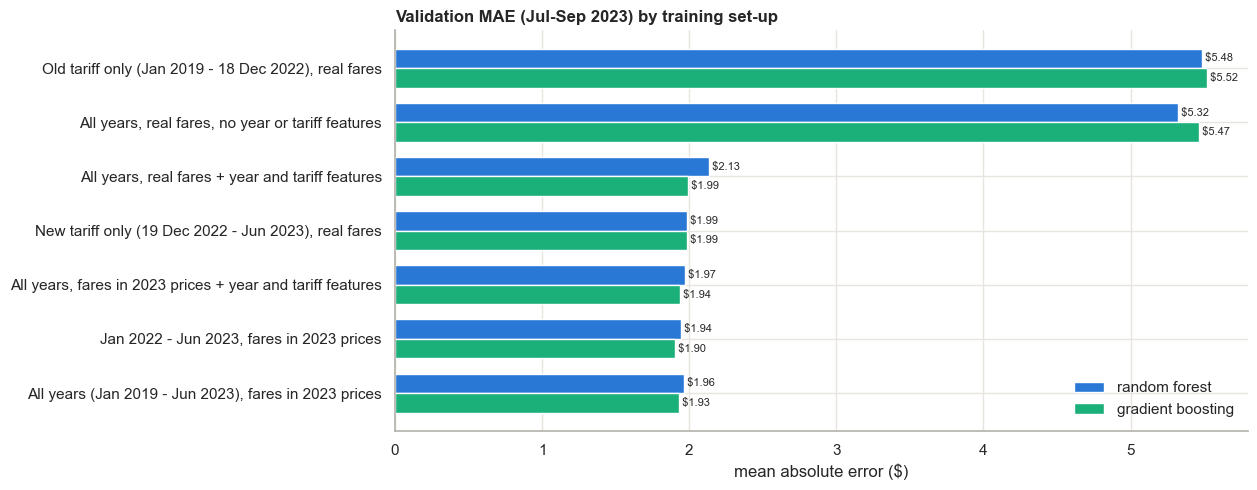

CPU times: user 5min 52s, sys: 33 s, total: 6min 26s
Wall time: 1min 13s


,training rows,gradient boosting: validation MAE ($),random forest: validation MAE ($)
training data and target,,,
"Old tariff only (Jan 2019 - 18 Dec 2022), real fares",150000,5.520,5.485
"All years, real fares, no year or tariff features",150000,5.469,5.322
"All years, real fares + year and tariff features",150000,1.993,2.133
"New tariff only (19 Dec 2022 - Jun 2023), real fares",150000,1.986,1.988
"All years, fares in 2023 prices + year and tariff features",150000,1.939,1.973
"Jan 2022 - Jun 2023, fares in 2023 prices",150000,1.902,1.944
"All years (Jan 2019 - Jun 2023), fares in 2023 prices",150000,1.929,1.962


In [53]:
%%time
n_probe = 150_000
with_period = M_NUM + M_PERIOD
setups = [
    ("Old tariff only (Jan 2019 - 18 Dec 2022), real fares", fit_pool[fit_pool.new_tariff == 0], TARGET, with_period),
    ("All years, real fares, no year or tariff features", fit_pool, TARGET, M_NUM),
    ("All years, real fares + year and tariff features", fit_pool, TARGET, with_period),
    ("New tariff only (19 Dec 2022 - Jun 2023), real fares", fit_pool[fit_pool.new_tariff == 1], TARGET, with_period),
    ("All years, fares in 2023 prices + year and tariff features", fit_pool, TRAIN_TARGET, with_period),
    ("Jan 2022 - Jun 2023, fares in 2023 prices", fit_pool[fit_pool.pickup_year >= 2022], TRAIN_TARGET, M_NUM),
    ("All years (Jan 2019 - Jun 2023), fares in 2023 prices", fit_pool, TRAIN_TARGET, M_NUM),
]
probe_models = {   # two quick tree models with fixed settings, used only for this decision
    "gradient boosting": lambda num: make_pipeline(preprocess(scale=False, num=num),
        HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE)),
    "random forest": lambda num: make_pipeline(preprocess(scale=False, num=num),
        RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=1.0, n_jobs=-1, random_state=RANDOM_STATE)),
}
probe = []
for label, pool, target, num in setups:
    d = pool.sample(min(n_probe, len(pool)), random_state=RANDOM_STATE)
    cols_used = num + M_RATE + M_ZONE
    row = {"training data and target": label, "training rows": len(d)}
    for mname, make in probe_models.items():
        p = make(num).fit(d[cols_used], d[target]).predict(valid_pool[cols_used])
        row[f"{mname}: validation MAE ($)"] = mean_absolute_error(valid_pool[TARGET], p)
    probe.append(row)
probe = pd.DataFrame(probe).set_index("training data and target")

fig, ax = plt.subplots(figsize=(11, 5.2))
yy = np.arange(len(probe))[::-1]
for k, (col, colour) in enumerate([("random forest: validation MAE ($)", BLUE),
                                   ("gradient boosting: validation MAE ($)", AQUA)]):
    ys = yy + (0.5 - k) * 0.36
    ax.barh(ys, probe[col], height=0.36, color=colour, label=col.split(":")[0])
    for yv, v in zip(ys, probe[col]): ax.text(v, yv, f" ${v:.2f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(probe.index)
ax.set(title="Validation MAE (Jul-Sep 2023) by training set-up", xlabel="mean absolute error ($)")
ax.legend(frameon=False, loc="lower right")
plt.show()
probe.round(3)

**Result** (validation MAE, gradient boosting / random forest):
- **A model trained before the increase fails:** old-tariff trips only give $5.54 / $5.48, almost three times the best set-up, because the model prices 2023 trips at 2019–2022 rates. Ignoring the change (real fares, no year or tariff features) is just as bad: $5.46 / $5.32.
- **Telling the model the period** (year and tariff features) fixes most of it for gradient boosting ($1.99) but less for the random forest ($2.13): a tree has to learn the old and the new price of every kind of trip separately.
- **Keeping only new-tariff trips** gives $1.99 / $1.99: the right prices, but only six months of data.
- **Converting older fares to 2023 prices is best for both models** ($1.91–$1.95 / $1.94–$1.97 across the three converted set-ups). For the random forest, it cuts the error by 8% compared with real fares plus the period features ($2.13 → $1.96).
- **Once fares are converted, the year and tariff features are no longer needed:** with all five years, dropping them lowers the error slightly ($1.95 → $1.93 and $1.97 → $1.96), because the conversion has already removed the price difference they stood for. Section 10.4 shows that for the neural network they also make the result depend on the random start.
- **How far back the data goes matters little:** January 2022 – June 2023 alone is about 1% better than all five years ($1.91 / $1.94 against $1.93 / $1.96).

**Choice:** every model in sections 10.3–10.7 learns from **all five years, with fares converted to 2023 prices (`fare_2023`) and without the year and tariff features** (14 inputs). The 2022–2023 window scores about 2 cents per trip better here, but using all five years is the aim of the project, covers every season several times over, and is within about 1% of that window for both models. The test months were not used for this decision.

### 10.3 Comparison models: predict-the-median and linear regression

These are **not** analysis methods. They set the bar the real methods must beat. A model that can't beat linear regression isn't worth its extra complexity.

In [54]:
baseline, t = fit_timed(DummyRegressor(strategy="median"), X_train, y_train)
display(evaluate("Baseline: median fare", baseline, t))
linreg, t = fit_timed(make_pipeline(preprocess(), LinearRegression()), X_train, y_train)
evaluate("Linear regression (comparison)", linreg, t)

,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Baseline: median fare,10.123,17.694,-0.167,18.311,14.181,8.910,200000,0.032,0.004


,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Linear regression (comparison),2.846,4.919,0.910,52.672,40.882,2.349,200000,0.158,0.052


### 10.4 Method 1: neural network (multi-layer perceptron)

A feed-forward network: the inputs pass through hidden layers of neurons with ReLU activations, and a single output neuron gives the fare. Weights are learned with the Adam optimiser by minimising squared error.

**Step 1: tune the architecture.** Grid search over network size and L2 penalty (`alpha`): fit on 40,000 January 2019 – June 2023 trips, score on 20,000 July–September 2023 trips.

In [55]:
%%time
nn_base = make_pipeline(preprocess(), MLPRegressor(
    activation="relu", solver="adam", batch_size=512, learning_rate_init=1e-3,
    max_iter=200, early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
    random_state=RANDOM_STATE))
Xg, yg, cv_split = tune_data(N_TUNE_FIT, N_TUNE_VAL)
nn_grid = GridSearchCV(nn_base, {
    "mlpregressor__hidden_layer_sizes": [(32,), (64, 32), (128, 64, 32)],
    "mlpregressor__alpha": [1e-4, 1e-2],
}, cv=cv_split, scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xg, yg)
print("best:", nn_grid.best_params_)
show_grid(nn_grid)

best: {'mlpregressor__alpha': 0.01, 'mlpregressor__hidden_layer_sizes': (128, 64, 32)}
CPU times: user 1min 11s, sys: 4.08 s, total: 1min 15s
Wall time: 20.7 s


,alpha,hidden_layer_sizes,mean_fit_time,validation MAE ($)
5,0.010,"(128, 64, 32)",6.644,2.031
2,0.000,"(128, 64, 32)",5.670,2.033
4,0.010,"(64, 32)",4.791,2.035
1,0.000,"(64, 32)",4.749,2.041
3,0.010,"(32,)",4.122,2.071
0,0.000,"(32,)",3.846,2.087


**Step 2: does the result depend on the random start?** A network starts from random weights, so two runs with different seeds can end up in different places. The cell below trains the chosen network with four seeds on the same tuning trips, once with the 14 inputs used here and once with `pickup_year` and `new_tariff` added back, and scores each on the same July–September 2023 trips.

In [56]:
%%time
seed_fit = fit_pool.sample(N_TUNE_FIT, random_state=RANDOM_STATE)      # the same rows as the grid search
seed_val = valid_pool.sample(N_TUNE_VAL, random_state=RANDOM_STATE)
seed_check = []
for label, num in [("14 inputs (used)", M_NUM), ("+ pickup_year and new_tariff", M_NUM + M_PERIOD)]:
    cols = num + M_RATE + M_ZONE
    for seed in [42, 0, 1, 2]:
        est = make_pipeline(preprocess(num=num), clone(nn_grid.best_estimator_[-1]).set_params(random_state=seed))
        est.fit(seed_fit[cols], seed_fit[TRAIN_TARGET])
        seed_check.append({"inputs": label, "seed": seed,
                           "validation MAE ($)": mean_absolute_error(seed_val[TARGET], est.predict(seed_val[cols]))})
seed_check = pd.DataFrame(seed_check)
display(seed_check.pivot(index="seed", columns="inputs", values="validation MAE ($)").round(3))
seed_check.groupby("inputs")["validation MAE ($)"].agg(["mean", "std", "min", "max"]).round(3)

inputs,+ pickup_year and new_tariff,14 inputs (used)
seed,,
0,2.142,2.043
1,2.256,2.034
2,2.195,2.021
42,2.232,2.031


CPU times: user 12min 17s, sys: 39.3 s, total: 12min 56s
Wall time: 1min 54s


,mean,std,min,max
inputs,,,,
+ pickup_year and new_tariff,2.206,0.050,2.142,2.256
14 inputs (used),2.032,0.009,2.021,2.043


**Result:** with the 14 inputs, the four random starts land within $0.02 of each other ($2.02–$2.04, standard deviation $0.01). With `pickup_year` and `new_tariff` added back, the same network is worse and much less stable: $2.14–$2.26 depending on the seed (standard deviation $0.05), $0.17 worse on average.

The reason is extrapolation. The validation and test trips are the newest in the data, and their combination of year, price list and month (2023, new prices, July–December) never occurs in training. A network is a smooth function, so for such inputs it extends whatever trend it learned, and that trend depends on where training happened to start. A tree model can't extrapolate (it predicts the average of similar training trips), which is why the period features did far less harm to the trees in section 10.2. Once fares are converted to 2023 prices the two features carry no price information, so **the network gets the 14 inputs only**.

**Step 3: how much training data is enough?** We have about two million sampled trips for January 2019 – September 2023. The cell below trains the chosen network, and linear regression for comparison, on growing samples of January 2019 – June 2023 trips and scores each on 50,000 July–September 2023 trips. If the error stops falling, more data only costs time.

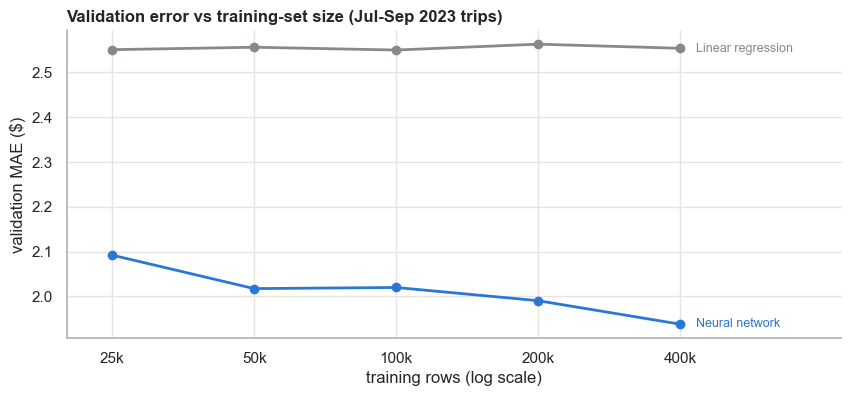

CPU times: user 15min 4s, sys: 49.4 s, total: 15min 54s
Wall time: 2min 8s


model,Linear regression,Neural network
training rows,,
25000,2.550,2.092
50000,2.555,2.018
100000,2.549,2.020
200000,2.562,1.991
400000,2.553,1.938


In [57]:
%%time
val_sample = valid_pool.sample(min(50_000, len(valid_pool)), random_state=RANDOM_STATE)
curve = []
for n in [25_000, 50_000, 100_000, 200_000, 400_000]:
    tr = fit_pool.sample(n, random_state=RANDOM_STATE)
    for label, est in [("Neural network", clone(nn_grid.best_estimator_)),
                       ("Linear regression", make_pipeline(preprocess(), LinearRegression()))]:
        est.fit(tr[M_FEATURES], tr[TRAIN_TARGET])
        curve.append({"model": label, "training rows": n,
                      "validation MAE ($)": mean_absolute_error(val_sample[TARGET], est.predict(val_sample[M_FEATURES]))})
curve = pd.DataFrame(curve).pivot(index="training rows", columns="model", values="validation MAE ($)")
fig, ax = plt.subplots(figsize=(10, 4))
for col, colour in [("Neural network", BLUE), ("Linear regression", GREY)]:
    ax.plot(curve.index, curve[col], color=colour, lw=2, marker="o", ms=6)
    ax.text(curve.index[-1] * 1.08, curve[col].iloc[-1], col, color=colour, va="center", fontsize=9)
ax.set(xscale="log", title="Validation error vs training-set size (Jul-Sep 2023 trips)", xlabel="training rows (log scale)",
       ylabel="validation MAE ($)", xlim=(curve.index[0] * 0.8, curve.index[-1] * 2.2))
ax.set_xticks(curve.index); ax.set_xticklabels([f"{n // 1000}k" for n in curve.index])
ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
plt.show()
curve.round(3)

**Result:** the network's validation error falls from $2.09 with 25,000 training rows to $1.99 with 200,000 and $1.94 with 400,000: doubling from 200,000 to 400,000 still gains about 3%, for twice the training time. Linear regression doesn't change at all ($2.55–$2.56), because a straight-line model is limited by its shape, not by data. **Every model is trained on the same 200,000 trips:** that keeps the methods comparable and the notebook's run time near 20 minutes. A production model could use more rows for a few percent more accuracy.

**Step 4: retrain the best network on the 200,000-trip January 2019 – September 2023 sample and predict October–December 2023.**

In [58]:
nn, t = fit_timed(clone(nn_grid.best_estimator_), X_train, y_train)
mlp = nn[-1]
print(f"stopped after {mlp.n_iter_} epochs; best internal validation R² = {max(mlp.validation_scores_):.4f}")
evaluate("Neural network", nn, t)

stopped after 39 epochs; best internal validation R² = 0.9641


,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Neural network,2.240,3.818,0.946,64.153,49.323,1.776,200000,27.541,0.114


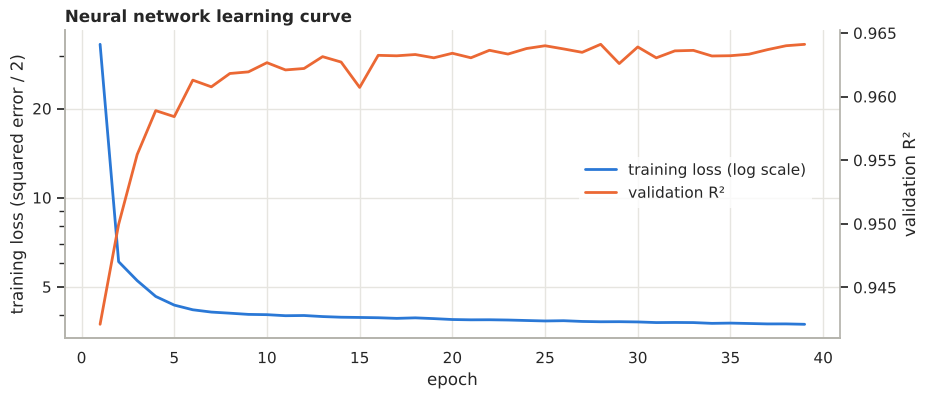

In [58]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, color=BLUE, lw=2, label="training loss (log scale)")
ax1.set(title="Neural network learning curve", xlabel="epoch", ylabel="training loss (squared error / 2)", yscale="log")
ax1.yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax1.yaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
lo, hi = min(mlp.loss_curve_), max(mlp.loss_curve_)
ax1.set_yticks([v for v in [1, 2, 5, 10, 20, 50, 100, 200, 500] if lo * 0.9 <= v <= hi * 1.1] or [round(lo, 1), round(hi, 1)])
ax2 = ax1.twinx()
ax2.plot(range(1, len(mlp.validation_scores_) + 1), mlp.validation_scores_, color=ORANGE, lw=2, label="validation R²")
ax2.set_ylabel("validation R²"); ax2.grid(False); ax2.spines["right"].set_visible(True)
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5), frameon=True, facecolor="white", edgecolor="none")
plt.show()

#### Write-up: neural network

**What we did**
1. Built a pipeline: standard-scale the numeric inputs, one-hot encode rate code, target-encode the two zone columns, then an `MLPRegressor` (ReLU hidden layers, Adam optimiser, mini-batches of 512, squared-error loss).
2. Tuned the architecture and L2 penalty with a grid search (3 sizes × 2 penalties): fit on 40,000 January 2019 – June 2023 trips, score on 20,000 July–September 2023 trips. **Three hidden layers of 128, 64 and 32 neurons with `alpha = 0.01`** scored best (validation MAE $2.03). The four two- and three-layer settings were within $0.01 of each other, so the exact size matters little; a single layer was clearly worse ($2.07–$2.09).
3. Checked the effect of the random start with four seeds: stable with the 14 inputs ($2.02–$2.04), but not with the year and tariff features added back ($2.14–$2.26). So the network gets no year or tariff input.
4. Checked how many training rows are needed (chart above): going from 200,000 to 400,000 rows lowers the validation error by about 3%.
5. Retrained the network on 200,000 trips from January 2019 – September 2023, with fares in 2023 prices. Early stopping held back 10% of them and stopped training after 39 epochs (internal validation R² 0.964).
6. Predicted the fares of the 93,033 October–December 2023 test trips.

**Accuracy (October–December 2023 test trips)**
- MAE **$2.24**, RMSE $3.82, **R² = 0.946**.
- **64.2%** of trips predicted within $2 of the real fare, and 49.3% within 10%.
- 21% less error than linear regression (MAE $2.85) and 78% less than always predicting the median fare ($10.12).

**Is it a good model?** Yes. It explains about 95% of the variation in late-2023 fares, and the typical miss of $2.24 is about 11% of the average test fare ($19.49). It is a close second to the random forest on MAE ($0.05 behind) and has the lowest RMSE ($3.82) and highest R² of all models, so it makes the fewest very large misses. It is small and fast: it predicts 93,000 trips in about 0.1 seconds. Its training error ($1.78) is below its test error ($2.24). Part of that gap is over-fitting, and part is the test period having the slowest traffic of the five years (section 9.3): the same network trained on 200,000 earlier trips scored $1.99 on July–September 2023. Its weak spots are **negotiated fares** (129 test trips averaging $72.68, missed by $23.78 on average), the 20 Nassau/Westchester trips, and the $70 JFK flat fare, which it prices less exactly than the random forest (average miss $0.83 against $0.04).

**Choices and why**
- **Scaling the inputs** is required for neural networks. Gradient descent converges badly when one input (distance, up to 100 miles) is on a different scale from another (a 0/1 flag).
- **Fares in 2023 prices** (section 5.4) as the training target, so all five years teach the network the current price list. Section 10.2 showed this beats the alternatives.
- **No year or tariff inputs.** Once fares are in 2023 prices they carry no price information, and Step 2 showed they make the network extrapolate: its error then depends on the random seed ($2.14–$2.26) and is $0.17 worse on average.
- **Hour and month as sine/cosine** so the network sees 23:00 next to 00:00 and December next to January.
- **Target encoding for zones** instead of ~520 one-hot columns, which keeps the network small and fast.
- **Early stopping** instead of a fixed number of epochs, to stop before the network starts memorising the training data.
- **200,000 training trips,** the same as every other model, so the comparison is fair. 400,000 would gain about 3% for twice the training time.
- **One limitation to state:** `trip_distance` is the distance the meter recorded *after* the trip. A real up-front fare estimate would use the route planner's distance, so real-world error would be somewhat higher. This applies to every model here.

### 10.5 Method 2: support vector machine (support vector regression, SVR)

SVR fits a function that keeps as many training points as possible inside a tube of width ±ε around it, and only points outside the tube (the *support vectors*) shape the model. With an **RBF kernel** it can bend to fit non-linear patterns. `C` sets how strongly points outside the tube are penalised, and `gamma` sets how local the kernel is.

**The big constraint is size.** Kernel SVR training time grows between n² and n³, and prediction time grows with the number of support vectors. The cell below measures this directly.

In [59]:
svr_timing = []
for n in [2_500, 5_000, 10_000]:
    s = fit_pool.sample(n, random_state=RANDOM_STATE)
    m = TransformedTargetRegressor(make_pipeline(preprocess(), SVR(C=10, gamma=0.02, epsilon=0.05, cache_size=1000)),
                                   transformer=StandardScaler())
    _, t = fit_timed(m, s[M_FEATURES], s[TRAIN_TARGET])
    svr_timing.append({"training rows": n, "fit time (s)": round(t, 1)})
pd.DataFrame(svr_timing)

,training rows,fit time (s)
0,2500,0.300
1,5000,0.800
2,10000,2.900


Each doubling of the rows makes the fit several times slower, so fitting on 200,000 rows would take hours. Two ways around it, and we use both:

- **Kernel SVR (RBF) on a 20,000-trip sample**: tuned with a grid search (fit on 8,000 January 2019 – June 2023 trips, score on 4,000 July–September 2023 trips).
- **Linear SVM (`LinearSVR`) on the full 200,000 trips**: same ε-insensitive loss, but a straight-line model that trains much faster.

**Choice: scale the target.** SVR's `C` and `epsilon` are in the units of the target. Fares range from $2.50 to $500, so the target is standardised (`TransformedTargetRegressor`) to make `epsilon = 0.05` mean "0.05 standard deviations" (well under a dollar).

In [60]:
%%time
svr_base = TransformedTargetRegressor(
    make_pipeline(preprocess(), SVR(kernel="rbf", epsilon=0.05, cache_size=1000)), transformer=StandardScaler())
Xg, yg, cv_split = tune_data(N_SVR_TUNE_FIT, N_SVR_TUNE_VAL)
svr_grid = GridSearchCV(svr_base, {
    "regressor__svr__C": [1, 10, 100],
    "regressor__svr__gamma": [0.005, 0.02, 0.1],
}, cv=cv_split, scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xg, yg)
print("best:", svr_grid.best_params_)
show_grid(svr_grid)

best: {'regressor__svr__C': 100, 'regressor__svr__gamma': 0.005}
CPU times: user 5.89 s, sys: 179 ms, total: 6.07 s
Wall time: 31.5 s


,C,gamma,mean_fit_time,validation MAE ($)
6,100,0.005,4.689,2.133
7,100,0.020,8.384,2.145
4,10,0.020,3.187,2.157
3,10,0.005,2.508,2.308
1,1,0.020,2.236,2.311
5,10,0.100,5.023,2.362
2,1,0.100,2.480,2.389
0,1,0.005,2.111,2.472
8,100,0.100,18.749,2.575


In [ ]:
%%time
svr_rows = train.sample(N_SVR, random_state=RANDOM_STATE)       # random rows from all of Jan 2019 - Sep 2023
X_svr, y_svr = svr_rows[M_FEATURES], svr_rows[TRAIN_TARGET]
svr, t = fit_timed(clone(svr_grid.best_estimator_), X_svr, y_svr)
print(f"support vectors: {svr.regressor_[-1].support_.size:,} of {N_SVR:,} training rows")
display(evaluate("SVM: kernel SVR (RBF, 20k rows)", svr, t, X_svr, y_svr))

lsvr, t = fit_timed(TransformedTargetRegressor(
    make_pipeline(preprocess(), LinearSVR(C=1, epsilon=0.05, max_iter=5000, random_state=RANDOM_STATE)),
    transformer=StandardScaler()), X_train, y_train)
evaluate("SVM: linear SVR (200k rows)", lsvr, t)

support vectors: 13,142 of 20,000 training rows


#### Write-up: support vector machine

**What we did**
1. Used support vector **regression** (SVR), because the target is continuous, with the same pre-processing pipeline as the neural network. We also standardised the target.
2. Measured how training time grows with data size: 0.3 seconds for 2,500 rows, 1.3 s for 5,000 and 5.0 s for 10,000, so each doubling makes fitting about 4 times slower. Exact times vary by computer. At that rate, kernel SVR on 200,000 rows would take hours.
3. Tuned `C` (1, 10, 100) and the RBF `gamma` (0.005, 0.02, 0.1): fit on 8,000 January 2019 – June 2023 trips, score on 4,000 July–September 2023 trips. The best was **`C = 100`, `gamma = 0.005`** (validation MAE $2.13): a strong penalty on errors and a smooth kernel. The most local kernel (`gamma = 0.1`) was clearly worse ($2.36–$2.58), because it memorises the few thousand tuning trips.
4. Retrained the best SVR on 20,000 trips drawn at random from all of January 2019 – September 2023. It kept 13,152 of them (66%) as support vectors.
5. Also trained a **linear SVM** (`LinearSVR`) on all 200,000 training trips as a scalable alternative.

**Accuracy (October–December 2023 test trips)**

| | MAE | RMSE | R² | within $2 |
|---|---|---|---|---|
| Kernel SVR (RBF), 20k rows | **$2.35** | $4.13 | **0.937** | 64.3% |
| Linear SVR, 200k rows | $2.84 | $5.14 | 0.902 | 57.8% |

**Is it a good model?** The kernel SVR is good: R² 0.94, and only $0.11 behind the neural network despite seeing 10 times less data. It has the lowest error of all models on cheap trips under $10 ($0.99). It is the least practical model, though. Its prediction cost grows with the number of support vectors, so scoring 93,000 trips took **about 50 seconds**, against about 0.1 s for the neural network, and it can't be trained on the full data. The linear SVR scales easily but can only draw a straight line through the data. It can't capture the flat JFK fare (average miss $6.99 on JFK trips, against $0.59 for the kernel SVR) and is weak on fares above $40 ($6.55 average miss).

**Choices and why**
- **SVR, not SVC:** fare is a number, not a class.
- **RBF kernel:** fares have non-linear patterns (flat airport fares, night trips) that a linear SVM can't capture.
- **Subsample of 20,000 rows:** forced by the n²–n³ training cost. This is the main trade-off of using SVMs on large data.
- **Training rows drawn at random from all five years,** not only the most recent weeks, so every season, weekday and hour is represented. A kernel model can't extrapolate: far from all its support vectors, its prediction falls back towards a constant.
- **Standardised target:** `C` and `epsilon` are in the units of the target, so standardising makes `epsilon = 0.05` mean about 75 cents (0.05 of the training fares' $15 standard deviation) and makes `C` comparable across settings.
- **Why the linear SVR has a lower MAE ($2.84) but a higher RMSE ($5.14) than linear regression ($2.85 / $4.92):** the SVR's ε-insensitive loss grows linearly with the error, so it targets absolute errors and is less pulled by extreme fares. Least squares minimises squared errors instead.

### 10.6 Method 3: random forest

A random forest averages many decision trees. Each tree is grown on a bootstrap sample of the trips and considers a random subset of features at each split. Single trees over-fit, but averaging many de-correlated trees cancels most of that out. Trees handle non-linear effects and interactions on their own, for example "airport zone **and** JFK rate code → flat $70".

**Step 1: tune** the minimum leaf size (how fine the trees can split) and the share of features tried at each split.

In [ ]:
%%time
rf_base = make_pipeline(preprocess(scale=False),
                        RandomForestRegressor(n_estimators=100, n_jobs=1, random_state=RANDOM_STATE))
Xg, yg, cv_split = tune_data(N_TUNE_FIT, N_TUNE_VAL)
rf_grid = GridSearchCV(rf_base, {
    "randomforestregressor__min_samples_leaf": [1, 5, 20],
    "randomforestregressor__max_features": [0.33, 1.0],
}, cv=cv_split, scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xg, yg)
print("best:", rf_grid.best_params_)
show_grid(rf_grid)

best: {'randomforestregressor__max_features': 1.0, 'randomforestregressor__min_samples_leaf': 5}
CPU times: user 17.1 s, sys: 70.4 ms, total: 17.2 s
Wall time: 46.1 s


,max_features,min_samples_leaf,mean_fit_time,validation MAE ($)
4,1.000,5,11.871,2.022
0,0.330,1,5.393,2.041
3,1.000,1,14.906,2.047
1,0.330,5,4.004,2.066
5,1.000,20,8.573,2.102
2,0.330,20,3.330,2.188


**Step 2: retrain on the 200,000-trip January 2019 – September 2023 sample with 100 trees, and predict October–December 2023.**

In [ ]:
%%time
rf = clone(rf_grid.best_estimator_).set_params(randomforestregressor__n_jobs=-1)
rf, t = fit_timed(rf, X_train, y_train)
evaluate("Random forest", rf, t)

CPU times: user 1min 10s, sys: 209 ms, total: 1min 11s
Wall time: 36.8 s


,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Random forest,2.189,3.872,0.944,64.961,50.529,1.362,200000,35.379,1.049


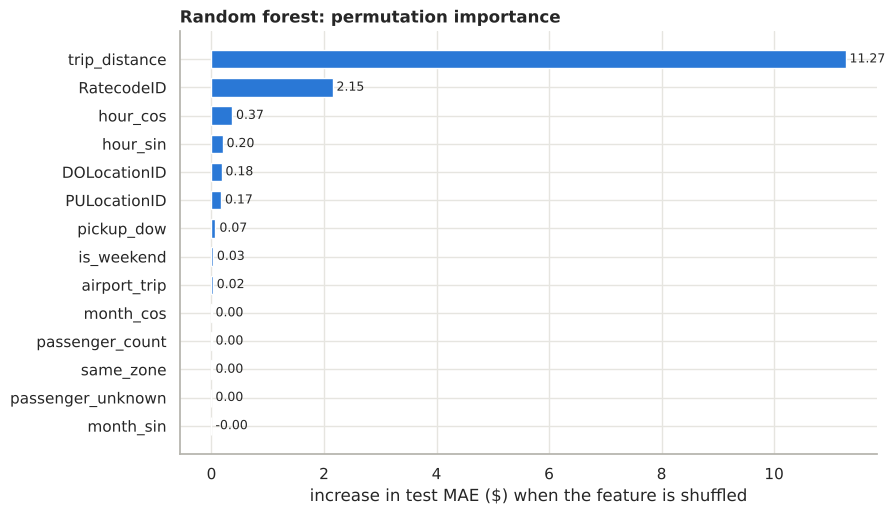

CPU times: user 25.4 s, sys: 611 ms, total: 26 s
Wall time: 14.1 s


,trip_distance,RatecodeID,hour_cos,hour_sin,DOLocationID,PULocationID,pickup_dow,is_weekend,airport_trip,month_cos,passenger_count,same_zone,passenger_unknown,month_sin
increase in test MAE ($),11.270,2.152,0.366,0.198,0.178,0.170,0.071,0.026,0.022,0.002,0.001,0.000,0.000,-0.000


In [64]:
%%time
# Permutation importance: how much the test MAE gets worse when one feature is shuffled
imp_idx = X_test.sample(min(20_000, len(X_test)), random_state=RANDOM_STATE).index    # 20k random test trips
imp_X, imp_y = X_test.loc[imp_idx], y_test.loc[imp_idx]
pi = permutation_importance(rf, imp_X, imp_y, scoring="neg_mean_absolute_error",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=M_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.65)
ax.set(title="Random forest: permutation importance", xlabel="increase in test MAE ($) when the feature is shuffled")
for i, v in enumerate(imp.values): ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
plt.show()
imp.sort_values(ascending=False).round(3).to_frame("increase in test MAE ($)").T

`month_sin` and `month_cos` take only three values in the test set (October, November and December), so shuffling them changes little and their importance is close to zero by construction. Their role is during training, where they separate the seasons of five years of trips.

#### Write-up: random forest

**What we did**
1. Used the same features with zones target-encoded and rate code one-hot, without scaling, since trees don't need it.
2. Tuned the minimum leaf size (1, 5, 20) and the share of features tried at each split (33% or 100%): fit on 40,000 January 2019 – June 2023 trips, score on 20,000 July–September 2023 trips. The best was **`min_samples_leaf = 5`, `max_features = 1.0`** (validation MAE $2.02), the same settings that won on 2019 alone. Fully grown trees (leaf size 1) were slightly worse ($2.04–$2.05), and leaf size 20 was clearly worse ($2.10–$2.19).
3. Retrained with **100 trees** on the 200,000-trip January 2019 – September 2023 sample (fares in 2023 prices) and predicted October–December 2023.
4. Measured **permutation importance**: how much the test error grows when one feature's values are shuffled.

**Accuracy (October–December 2023 test trips)**
- MAE **$2.19**, RMSE $3.87, **R² = 0.944**.
- **65.0%** of trips within $2, and 50.5% within 10%.
- **The best of all models** on MAE and on both "within" measures; the neural network has a slightly lower RMSE.

**Is it a good model?** Yes, the best one here. A typical miss is $2.19, 11% of the average test fare ($19.49): the same relative accuracy as the 2019-only analysis on December 2019. It is the most accurate model on special fares: it predicts the $70 JFK flat fare almost perfectly (average miss **$0.04**) and has the lowest error on fares above $40 ($3.39). Trees capture rules like "JFK rate code → $70 regardless of distance" directly. It does **over-fit somewhat**: training error $1.36 against $2.19 on the test months. Requiring at least 5 trips per leaf limits this compared with fully grown trees, and part of the gap again comes from the test months being the hardest of the five years. Its error rises through the test period ($2.05 in October, $2.16 in November, $2.36 in December) as the fares of similar trips spread out more (section 9.3). The drawbacks are size (100 deep trees need a lot of memory) and prediction time (about 1 second per 93,000 trips, against about 0.1 s for the neural network). The importance chart confirms the analysis in section 6: **trip distance dominates** (shuffling it adds $11.27 to the MAE), followed by **rate code** ($2.15) and **time of day** (hour cosine/sine $0.37 / $0.20). Passenger count adds nothing.

**Choices and why**
- **Random forest instead of a single decision tree:** a single deep tree has high variance, while averaging many trees on bootstrap samples reduces it without losing the ability to model interactions.
- **No scaling:** tree splits depend only on the order of values.
- **Fares in 2023 prices:** trees can't share a pattern between two price lists, so with real fares every leaf has to learn the old and the new price separately. In section 10.2, converting the fares cut the forest's validation error by 8% ($2.13 → $1.96).
- **No year or tariff features:** with converted fares they are not needed, and the forest did slightly better without them in section 10.2 ($1.97 → $1.96).
- **Leaf size chosen on the validation months** rather than the default of 1: it slightly improves accuracy and makes the forest smaller.
- **100 trees:** more trees barely change the average once the forest is this size, but cost time and memory.
- **Permutation importance instead of the built-in impurity importance:** impurity importance favours features with many distinct values, such as the zone encodings, while permutation importance measures the real effect on test error. Month shows (almost) zero only because it barely varies within the three test months.

### 10.7 Method 4: Ridge and Lasso regression

Both are linear regression with a penalty on the size of the coefficients, which reduces over-fitting:

- **Ridge** (L2 penalty `α·Σβ²`) shrinks all coefficients towards zero.
- **Lasso** (L1 penalty `α·Σ|β|`) can shrink coefficients to exactly zero, so it also does feature selection.

The penalty strength `α` is chosen on the validation months, like every other hyper-parameter: fit on January 2019 – June 2023, score on July–September 2023. Inputs are standardised first, which is required: otherwise the penalty would punish features just for being measured in small units.

In [ ]:
Xg, yg, cv_split = tune_data(N_TUNE_FIT, N_TUNE_VAL)
ridge_grid = GridSearchCV(make_pipeline(preprocess(), Ridge()), {"ridge__alpha": np.logspace(-3, 3, 13)},
                          cv=cv_split, scoring="neg_mean_absolute_error").fit(Xg, yg)
lasso_grid = GridSearchCV(make_pipeline(preprocess(), Lasso(max_iter=5000)), {"lasso__alpha": np.logspace(-4, 0, 20)},
                          cv=cv_split, scoring="neg_mean_absolute_error").fit(Xg, yg)

ridge, t = fit_timed(clone(ridge_grid.best_estimator_), X_train, y_train)
print(f"Ridge: chosen alpha = {ridge[-1].alpha:g}")
display(evaluate("Ridge regression", ridge, t))
lasso, t = fit_timed(clone(lasso_grid.best_estimator_), X_train, y_train)
print(f"Lasso: chosen alpha = {lasso[-1].alpha:g}; coefficients set to zero: "
      f"{(lasso[-1].coef_ == 0).sum()} of {lasso[-1].coef_.size}")
evaluate("Lasso regression", lasso, t)

Ridge: chosen alpha = 3.16228


,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Ridge regression,2.846,4.919,0.910,52.671,40.879,2.349,200000,0.155,0.027


Lasso: chosen alpha = 0.00183298; coefficients set to zero: 2 of 18


,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Lasso regression,2.849,4.935,0.909,52.682,40.852,2.349,200000,0.257,0.029


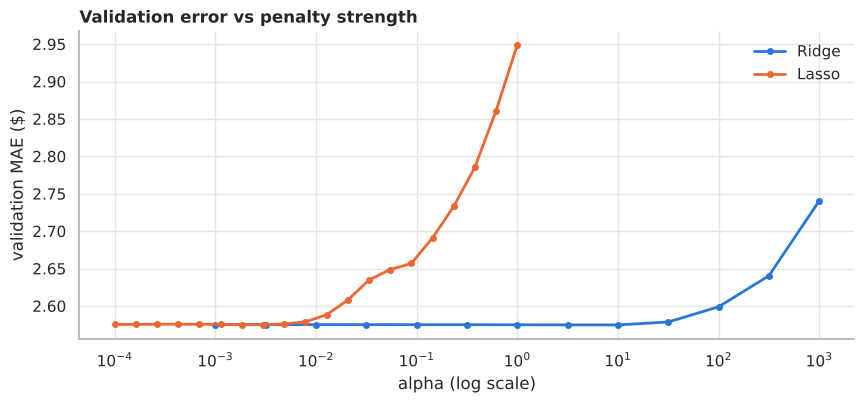

In [66]:
# Validation MAE for each alpha: how strong a penalty the data wants
alpha_curve = pd.DataFrame({
    "alpha": np.r_[ridge_grid.cv_results_["param_ridge__alpha"].astype(float),
                   lasso_grid.cv_results_["param_lasso__alpha"].astype(float)],
    "validation MAE ($)": -np.r_[ridge_grid.cv_results_["mean_test_score"], lasso_grid.cv_results_["mean_test_score"]],
    "model": ["Ridge"] * 13 + ["Lasso"] * 20})
fig, ax = plt.subplots(figsize=(10, 4))
for m, colour in [("Ridge", BLUE), ("Lasso", ORANGE)]:
    d = alpha_curve[alpha_curve.model == m]
    ax.plot(d.alpha, d["validation MAE ($)"], color=colour, lw=2, marker="o", ms=4, label=m)
ax.set(xscale="log", title="Validation error vs penalty strength", xlabel="alpha (log scale)", ylabel="validation MAE ($)")
ax.legend(frameon=False)
plt.show()

In [67]:
# Coefficients on the standardised inputs: dollars per 1 standard deviation of each input
names = [n.split("__")[-1] for n in linreg[0].get_feature_names_out()]
coefs = pd.DataFrame({"Linear": linreg[-1].coef_, "Ridge": ridge[-1].coef_, "Lasso": lasso[-1].coef_}, index=names)
print(f"1 SD of trip_distance in the training data = {X_train.trip_distance.std():.2f} miles")
coefs.reindex(coefs.Linear.abs().sort_values(ascending=False).index).round(3)

1 SD of trip_distance in the training data = 3.96 miles


,Linear,Ridge,Lasso
trip_distance,15.021,15.020,15.006
RatecodeID_3,12.602,12.611,15.421
RatecodeID_2,-7.762,-7.635,-3.829
RatecodeID_1,-5.014,-4.893,-1.159
RatecodeID_4,3.054,2.647,0.000
RatecodeID_5,-2.879,-2.730,0.000
hour_cos,-0.823,-0.823,-0.822
airport_trip,-0.647,-0.647,-0.641
is_weekend,-0.498,-0.498,-0.490
hour_sin,-0.440,-0.440,-0.438


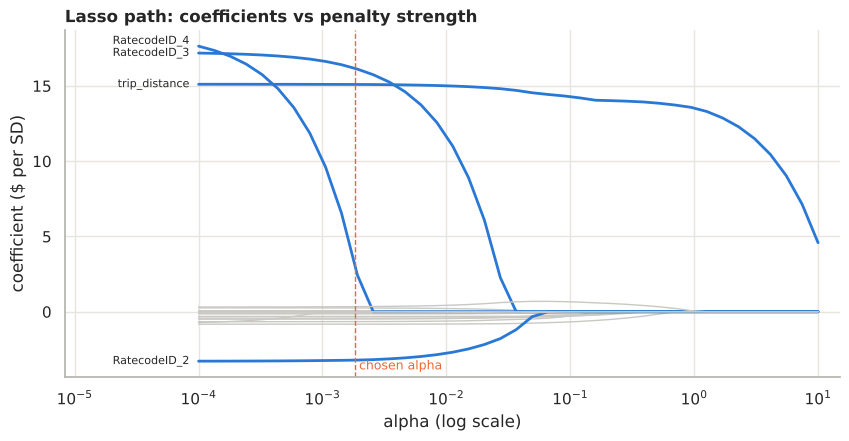

In [ ]:
# Lasso path: how each coefficient shrinks as alpha grows (bigger alpha = stronger penalty)
from sklearn.linear_model import lasso_path
Z = linreg[0].transform(X_train.iloc[:50_000]); yz = y_train.iloc[:50_000].values
alphas_p, path, _ = lasso_path(Z, yz - yz.mean(), alphas=np.logspace(-4, 1, 40))
fig, ax = plt.subplots(figsize=(10, 4.5))
top = np.argsort(-np.abs(path[:, -1]))[:4]
for i in range(path.shape[0]):
    ax.plot(alphas_p, path[i], color=BLUE if i in top else "#c9c8c2", lw=2 if i in top else 1)
placed = []
for yv, i in sorted((path[i, -1], i) for i in top):          # spread labels so they don't overlap
    yv = max(yv, placed[-1] + 0.8) if placed else yv
    placed.append(yv)
    ax.text(alphas_p[-1] * 0.9, yv, f"{names[i]} ", fontsize=8, va="center", ha="right")
ax.set_xlim(alphas_p[-1] / 12, alphas_p[0] * 1.5)
ax.set(xscale="log", title="Lasso path: coefficients vs penalty strength", xlabel="alpha (log scale)",
       ylabel="coefficient ($ per SD)")
ax.axvline(lasso[-1].alpha, color=ORANGE, ls="--", lw=1)
ax.text(lasso[-1].alpha, ax.get_ylim()[0] + 0.5, " chosen alpha", color=ORANGE, fontsize=9)
plt.show()

#### Write-up: Ridge and Lasso regression

**What we did**
1. Used the same pre-processing as the linear regression comparison model (all inputs standardised, so the penalty treats every feature equally).
2. Chose the penalty strength `α` on the validation months (fit January 2019 – June 2023, score July–September 2023): 13 values from 0.001 to 1,000 for Ridge, and 20 values from 0.0001 to 1 for Lasso.
3. Refitted both with the chosen `α` on the 200,000-trip training sample, predicted October–December 2023, and compared their coefficients with plain linear regression.

**Accuracy (October–December 2023 test trips)**
- Ridge (`α = 3.2`): MAE **$2.85**, RMSE $4.92, **R² = 0.910**, 52.7% within $2.
- Lasso (`α = 0.0018`): MAE **$2.85**, RMSE $4.93, **R² = 0.909**, 52.7% within $2. It set 2 of 18 coefficients to zero.
- Both are the same as linear regression (MAE $2.85, R² 0.910).

**Is it a good model?** Usable but clearly the weakest of the real methods: about $0.66 per trip worse than the random forest, and only 53% of trips within $2 (against 65%). Regularisation didn't help, and that is the expected result rather than a failure. Ridge and Lasso fix **over-fitting**, and a linear model with 18 coefficients and 200,000 rows has nothing to over-fit. The validation chart shows this: the error is flat for small penalties and only rises once the penalty is strong (Lasso above about α = 0.01, Ridge above about α = 30). The real limit is **under-fitting**: a straight line can't represent the flat JFK fare (average miss about $6.50 on JFK trips) or long expensive trips (about $6.30 average miss above $40), which is why the non-linear methods win. The gap between training error ($2.35) and test error ($2.85) comes from the test months being harder (section 9.3), not from over-fitting.

**What the coefficients show.** Trip distance has by far the largest effect: **$15.02 per standard deviation**. One standard deviation is 3.96 miles, so that is about **$3.79 per mile**, close to the 2023 meter rate of $3.50 per mile (five 70-cent units) plus time charges. The model has recovered the meter formula from the data, in 2023 prices because the target was converted. The one-hot rate-code coefficients look large and differ between the three models because those columns always sum to 1: they are perfectly collinear, so least squares can't pin down their individual values. Lasso settles this by setting two of them (Nassau/Westchester and negotiated) to zero, which is its feature-selection behaviour in action. The Lasso path chart shows the rate-code coefficients shrinking first as `α` grows, while trip distance survives up to very strong penalties.

**Choices and why**
- **Standardised inputs:** without them the penalty would punish a coefficient just because its feature is measured in small units.
- **α chosen on the validation months:** the same procedure as every other model, so the penalty isn't tuned on the test months.
- **Kept both methods:** together they show that the gap to the best models comes from model *shape* (non-linearity), not from over-fitting.

### 10.8 Comparing all models on the same October–December 2023 test trips

In [ ]:
summary = pd.DataFrame(results).T.sort_values("MAE ($)")
summary["train rows"] = summary["train rows"].astype(int)
summary.round({"MAE ($)": 3, "RMSE ($)": 3, "R²": 3, "within $2 (%)": 1, "within 10% (%)": 1,
               "train MAE ($)": 3, "fit (s)": 1, "predict (s)": 1})

,MAE ($),RMSE ($),R²,within $2 (%),within 10% (%),train MAE ($),train rows,fit (s),predict (s)
Random forest,2.189,3.872,0.944,65.000,50.500,1.362,200000,35.400,1.000
Neural network,2.240,3.818,0.946,64.200,49.300,1.776,200000,33.200,0.100
"SVM: kernel SVR (RBF, 20k rows)",2.345,4.125,0.937,64.300,49.200,1.767,20000,36.200,47.600
SVM: linear SVR (200k rows),2.840,5.135,0.902,57.800,43.700,2.221,200000,75.100,0.000
Linear regression (comparison),2.846,4.919,0.910,52.700,40.900,2.349,200000,0.200,0.000
Ridge regression,2.846,4.919,0.910,52.700,40.900,2.349,200000,0.200,0.000
Lasso regression,2.849,4.935,0.909,52.700,40.900,2.349,200000,0.300,0.000
Baseline: median fare,10.123,17.694,-0.167,18.300,14.200,8.910,200000,0.000,0.000


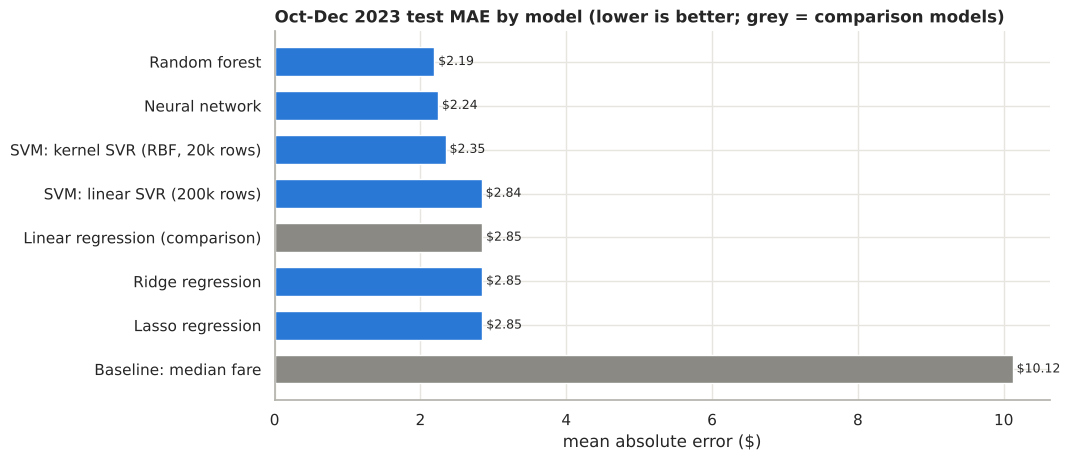

In [70]:
s = summary["MAE ($)"].sort_values(ascending=False)
comparison = {"Baseline: median fare", "Linear regression (comparison)"}
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(s.index, s.values, color=[GREY if n in comparison else BLUE for n in s.index], height=0.65)
for i, v in enumerate(s.values): ax.text(v, i, f" ${v:.2f}", va="center", fontsize=9)
ax.set(title="Oct-Dec 2023 test MAE by model (lower is better; grey = comparison models)", xlabel="mean absolute error ($)")
plt.show()

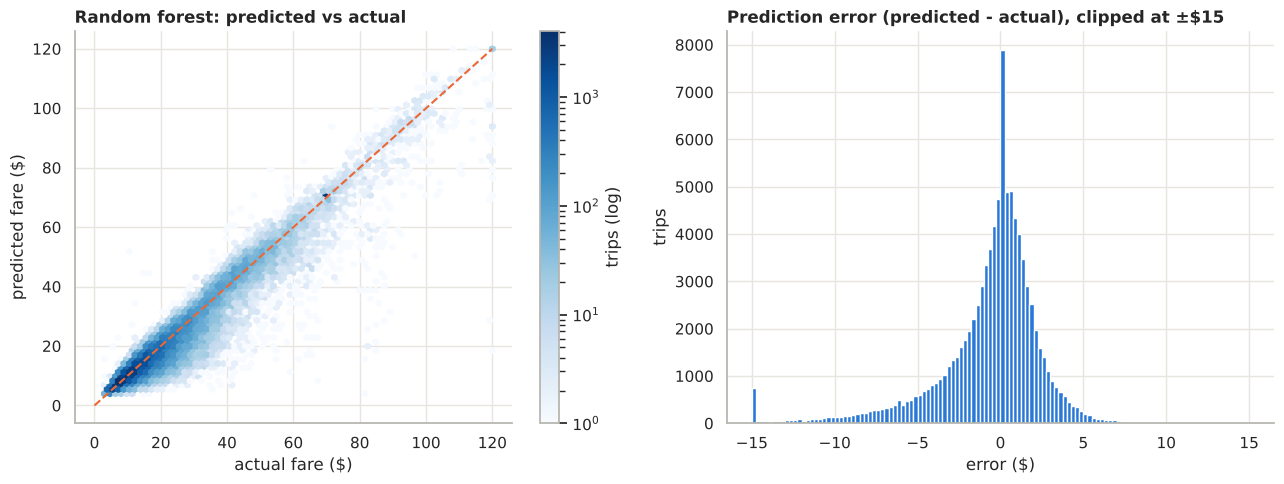

In [ ]:
best_name = summary.drop(index=list(comparison)).index[0]
p = predictions[best_name]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(y_test.clip(upper=120), np.clip(p, 0, 120), gridsize=70, bins="log", cmap="Blues", mincnt=1)
axes[0].plot([0, 120], [0, 120], color=ORANGE, lw=1.5, ls="--")
axes[0].set(title=f"{best_name}: predicted vs actual", xlabel="actual fare ($)", ylabel="predicted fare ($)")
fig.colorbar(hb, ax=axes[0], label="trips (log)")
resid = p - y_test.values
axes[1].hist(np.clip(resid, -15, 15), bins=120, color=BLUE)
axes[1].set(title="Prediction error (predicted - actual), clipped at ±$15", xlabel="error ($)", ylabel="trips")
plt.tight_layout(); plt.show()

In [72]:
# Where do the models go wrong? MAE by rate code, by fare band and by test month
rate_names = {1: "Standard", 2: "JFK", 3: "Newark", 4: "Nassau/West.", 5: "Negotiated", 6: "Group"}
grp = pd.DataFrame({"rate code": test.RatecodeID.map(rate_names).values,
                    "fare band": pd.cut(y_test.values, [0, 10, 20, 40, 1000], labels=["< $10", "$10-20", "$20-40", "> $40"]),
                    "month": test.tpep_pickup_datetime.dt.strftime("%b %Y").values})
names_show = [n for n in summary.index if n != "Baseline: median fare"]
def mae_by(col):
    t = pd.DataFrame({n: pd.Series(np.abs(predictions[n] - y_test.values)).groupby(grp[col].values, observed=True).mean()
                      for n in names_show})
    t.insert(0, "test trips", grp[col].value_counts())
    return t
by_rate, by_band, by_test_month = mae_by("rate code"), mae_by("fare band"), mae_by("month")
by_test_month = by_test_month.loc[sorted(by_test_month.index, key=lambda s: pd.Timestamp("1 " + s))]
display(by_rate.sort_values("test trips", ascending=False).round(2))
display(by_band.round(2))
by_test_month.round(2)

,test trips,Random forest,Neural network,"SVM: kernel SVR (RBF, 20k rows)",SVM: linear SVR (200k rows),Linear regression (comparison),Ridge regression,Lasso regression
Standard,89247,2.220,2.250,2.360,2.630,2.660,2.660,2.660
JFK,3376,0.040,0.830,0.590,6.990,6.470,6.470,6.460
Newark,261,4.940,3.890,4.930,4.420,4.510,4.470,4.230
Negotiated,129,29.940,23.780,25.930,34.650,30.270,30.240,31.020
Nassau/West.,20,29.170,21.260,41.560,33.520,28.260,28.620,33.510


,test trips,Random forest,Neural network,"SVM: kernel SVR (RBF, 20k rows)",SVM: linear SVR (200k rows),Linear regression (comparison),Ridge regression,Lasso regression
< $10,28641,1.040,1.070,0.990,1.180,1.820,1.830,1.820
$10-20,37391,1.950,1.980,2.040,2.100,1.800,1.800,1.800
$20-40,17402,3.930,4.020,4.450,5.120,4.880,4.880,4.890
> $40,9599,3.390,3.530,3.760,6.550,6.270,6.260,6.280


,test trips,Random forest,Neural network,"SVM: kernel SVR (RBF, 20k rows)",SVM: linear SVR (200k rows),Linear regression (comparison),Ridge regression,Lasso regression
Oct 2023,32021,2.050,2.110,2.200,2.710,2.720,2.720,2.720
Nov 2023,30559,2.160,2.220,2.330,2.810,2.820,2.820,2.820
Dec 2023,30453,2.360,2.390,2.520,3.010,3.000,3.000,3.010


In [73]:
# Average fare of the test trips by rate code, for context
test.groupby(test.RatecodeID.map(rate_names)).fare_amount.agg(["size", "mean", "median"]).round(2).sort_values("size", ascending=False)

,size,mean,median
RatecodeID,,,
Standard,89247,17.260,13.500
JFK,3376,70.000,70.000
Newark,261,92.310,91.600
Negotiated,129,72.680,80.000
Nassau/West.,20,109.500,118.150


#### Write-up: overall comparison

| Rank | Model | Test MAE | R² | Within $2 | Verdict |
|---|---|---|---|---|---|
| 1 | **Random forest** | **$2.19** | 0.944 | **65.0%** | Lowest average error, best on JFK and expensive fares; somewhat over-fits and is large |
| 2 | **Neural network** | $2.24 | **0.946** | 64.2% | Close second; fewest large misses (lowest RMSE); small, fast to predict |
| 3 | SVM (RBF kernel) | $2.35 | 0.937 | 64.3% | Accurate, but limited to 20k training rows and slow to predict |
| 4 | SVM (linear) | $2.84 | 0.902 | 57.8% | Scales, but can only fit straight lines |
| 5 | Ridge / Lasso | $2.85 / $2.85 | 0.910 / 0.909 | 52.7% / 52.7% | Same as linear regression: no over-fitting for the penalty to fix |
| – | Linear regression *(comparison)* | $2.85 | 0.910 | 52.7% | Bar to beat |
| – | Median fare *(baseline)* | $10.12 | −0.17 | 18.3% | Floor |

**Recommendation: the random forest**, with the neural network a close second. The forest has the lowest average error and handles the special fares best. The network is within $0.05 per trip, makes fewer very large errors, predicts about seven times faster and is far smaller to store, so it would be the better choice if speed or memory mattered.

**Five years help once the fares are on one price list (section 10.2).** A model trained only on trips from before the fare increase misses July–September 2023 fares by about $5.50 on average. Converting the older fares to 2023 prices brings that under $2 and lets all five years teach the current prices; with converted fares, the year and tariff features are no longer needed.

**Why these errors are higher than in the 2019 analysis ($1.45 on December 2019):** late-2023 fares are about 50% higher (average $19.49 against $13.13), and the test months fall in the slowest stretch of traffic of the five years (8.7–8.8 mph), so the time-based part of the fare varies most. Relative to the fare, the accuracy is about the same: the random forest's error is 11% of the average fare in both analyses, and the share of trips within 10% is similar (50.5% now, 51.3% then).

**Where every model struggles**
- **Negotiated fares** (129 test trips, average fare $72.68) are agreed with the driver, so nothing in the data predicts them. The models miss them by $24–35 on average.
- **Short trips** are hard in relative terms: being $1 off on a $6 fare is a 17% error. That is why only about half of the trips are within 10%, even though nearly two-thirds are within $2.
- **The end of the test period is hardest:** every model's error rises from October to December 2023 (random forest $2.05 → $2.36), as the fares of similar trips spread out most in December (section 9.3).
- **Very rare categories** such as Nassau/Westchester (20 test trips) have too little training data.

**Next steps:** add 2024–2025 (section 11) and check how the models cope with the January 2025 congestion-pricing charge; add a public-holiday feature for the Christmas period; and use route-planner distance instead of metered distance for a true up-front estimate.

## 11. Adding more years (2024 onwards)

The whole notebook is driven by a few settings in the setup cell (section 1), so adding years is mostly configuration:

1. Put the new monthly files in `DATA_DIR` with their original names (also the missing month, if any: section 1 lists it).
2. Add the years to `YEARS` in the setup cell, for example `YEARS = [2019, 2020, 2021, 2022, 2023, 2024]`. The sample file name includes the years, and section 5.3 rebuilds the sample whenever it doesn't match the files in the folder.
3. Keep `SAMPLE_FRAC = 0.01` (1% of six years is still well over two million trips) or lower it on a small laptop.
4. Move the split dates in section 9.4 forward, so the test set is again the most recent quarter, for example:

```python
TRAIN_END = pd.Timestamp(2024, 7, 1)    # train: Jan 2019 - Jun 2024
VALID_END = pd.Timestamp(2024, 10, 1)   # validate: Jul-Sep 2024, test: Oct-Dec 2024
```

**What to watch for in later years**
- **New columns.** The 2025 files add `cbd_congestion_fee`, the Manhattan congestion-pricing charge that started on 5 January 2025. `load_month` already keeps it (and fills 0 before it existed). Like the other surcharges, it is part of the bill, not of `fare_amount`, so it is not a feature.
- **More schema drift.** Run section 1.1 first: it lists every schema version and what changed.
- **Another fare change.** If the TLC changes the meter rates again, add the new date and prices to `harmonise_fare` (section 5.4) so that all years are converted to the newest price list.
- **Report error per period**, as in section 10.8, so that drift is visible instead of averaged away.
- **Use DuckDB for summaries** across all years, as in sections 2, 5, 8 and 9.1. It scales to hundreds of millions of rows without extra memory; raise `DUCKDB_MEMORY` if a query runs out of memory.

## 12. Summary of answers

| Question | Answer |
|---|---|
| **Data** | 60 monthly TLC files, January 2019 – December 2023: 218,118,168 trips, 3.3 GB, in three schema versions. Exact statistics with DuckDB; a 1% sample of every month (2,051,026 trips after cleaning) for charts and models. |
| **Target variable** | `fare_amount` (main). The models learn it converted to the 2023 meter prices (`fare_2023`, section 5.4) and are scored on real 2023 fares. Alternatives: `trip_duration` (ETA), or `tip_amount > 0` for card trips. |
| **Regression or classification** | **Regression** (continuous dollars). The tip alternative would be binary classification. |
| **Missing data** | Exact over all 218.1 M trips: `airport_fee` 53.9% null (the fee only exists from 2021) → fill 0; `congestion_surcharge` 4.7% null (January 2019, before it existed, and rows without a meter record) → fill 0; 2.48% of trips have no meter record (`passenger_count`, `RatecodeID` and `store_and_fwd_flag` all null, `payment_type` 0; up to 17% in May 2020) → drop; disguised missing: `passenger_count = 0` (1.86%) → impute 1 + flag; `RatecodeID = 99`, zones 264/265, zero or negative distance, non-positive fares, negative charges → drop. Cleaning removes 6.0% of sampled trips (3.4% in 2019, 6.4–8.1% in 2020–2023). |
| **Relevant variables** | `trip_distance`, pickup/dropoff zones, `RatecodeID`, pickup hour/day, month, airport and same-zone flags. Year and the tariff flag matter for the real fare, but are not needed once fares are converted to 2023 prices (section 10.2). |
| **Irrelevant / excluded** | `VendorID`, `store_and_fwd_flag` (irrelevant); `tip_amount`, `tolls_amount`, `total_amount`, surcharges, `payment_type`, dropoff time/duration (leakage). |
| **Validation** | Chronological split by whole months: tune on January 2019 – June 2023 vs July–September 2023 (`PredefinedSplit`), refit on January 2019 – September 2023, test once on October–December 2023. `TimeSeriesSplit` demonstrated in section 7. Preprocessing inside a `Pipeline`; error reported per test month to expose drift. |
| **Visualisation** | Five years: missing values, fare distribution, fare vs distance before and after the fare increase, trips by hour, weekday and day (COVID, holidays, fare increase marked), fare by hour and rate code, payment and tips by year, top pickup zones, correlation heatmap; month by month: trips, median fare, distance, surcharges, missing records, traffic speed and fare spread, the split. |
| **Modelling** | Random forest (October–December 2023 test MAE $2.19, R² 0.944), neural network ($2.24, 0.946), kernel SVM ($2.35, 0.937), linear SVM ($2.84, 0.902), Ridge/Lasso ($2.85/$2.85, 0.910/0.909), against linear regression ($2.85, 0.910) and a median baseline ($10.12). Recommended: the random forest, with the neural network a close second. All models learn from five years of trips with fares converted to 2023 prices and 14 pickup-time inputs (no year or tariff flag), chosen on the validation months (section 10.2). |